In [1]:
# ============================================================================
# DISORDERED CULTURE ANALYSIS (expD1): does the signaling -> fate model
# generalize to non-micropatterned (disordered) cultures?
#
# Q1: Can fate be predicted from signaling with similar accuracy in disordered
#     cultures as in micropatterned ones?
# Q2: Does cross-experiment prediction work between disordered and
#     micropatterned cultures, in both directions?
#
# Reuses IIF_analysis.py wherever possible (VIB training/self-CV, cross-
# experiment alignment, run_vib_cross_experiment). Two deliberate departures
# from the established (fig3/4/5) convention:
#
#   - expD1's two labeled conditions ('60k','90k') are BOTH the biological
#     equivalent of B50 (unperturbed) -- they differ only in seeding density,
#     not in any signaling perturbation/treatment. There is no row literally
#     labeled 'B50' in the raw file, so the standard exp_loader/ExperimentConfig
#     pipeline (which defaults to normalization_condition='B50') can't be used
#     as-is. Since both conditions are the same underlying biological
#     condition, pooling them as a single alignment/threshold anchor (below)
#     is the natural choice, not a workaround for a real missing-baseline gap.
#     NOTE: seeding density and REALIZED (final, per-colony) density did NOT
#     correlate well in practice -- don't treat the 60k/90k LABELS as a clean
#     density split; the diagnostic cell below uses actual per-colony cell
#     counts, not the label, as the real density covariate. The two labels
#     are kept separate only as a grouping variable (e.g. for comparing
#     self-CV accuracy side by side), not because they're different
#     conditions biologically.
#
#   - No micropattern geometry exists for disordered cells (no defined colony
#     edge/center), so ExperimentResults/create_experiment (which hardcode
#     nominalRadius=350 and compute radial profiles) are NOT used for expD1.
#     All spatial/radial analysis is skipped entirely for this experiment;
#     only per-cell signal/gene values and 'Colony' (as a replicate/grouping
#     variable for leave-one-colony-out CV, NOT a geometric unit) are used.
#
# run_vib_cross_experiment/fit_zscore_alignment/fit_gene_alignment were
# extended (IIF_analysis.py) with independent train_condition/test_condition
# (condition_self/condition_ref) parameters to support this -- both default
# to 'B50', so every existing caller elsewhere is unaffected.
#
# pSMAD1: expD1's raw file has THREE candidate columns -- pSMAD1_1 (rd3
# stain), pSMAD1_2 (rd6 re-stain), pSMAD1n5 (a different pSMAD1/5 antibody
# tried in rd7, untested elsewhere). Per Hina/Idse's discussion, initial
# consensus leaned rd6 as less grainy but with more junk cells -- empirically
# checked instead (three "pSMAD1 candidate comparison" cells right after
# loading): junk fraction is 0% for all three (junk was already filtered out
# upstream of this CSV, so that concern doesn't apply here), and pSMAD1_1 has
# the most complete data (0% NaN vs 2.2-2.6% for the others) with the best/
# tied-best self-CV accuracy. WINNING_PSMAD1 is set to pSMAD1_1 accordingly --
# the "less grainy" rationale for rd6 wasn't supported by this comparison,
# though it may still matter for something this comparison doesn't test
# (e.g. visual graininess in a figure, as opposed to downstream prediction
# accuracy).
# ============================================================================

In [2]:
import os
import sys
import importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score

sys.path.append('/Users/idse/repos/signaldecoding/2D_gastruloids_v5')
import IIF_analysis as IIF
importlib.reload(IIF)

device = 'mps' if torch.backends.mps.is_available() else 'cpu'
dataDir = '/Users/idse/data_tmp/signaldecoding/'

## Data loading & QC

In [3]:
# ============================================================
# Load Exp20 (micropattern reference) -- exact same config entry as fig5n.ipynb,
# so results here are directly comparable to that notebook's numbers.
# ============================================================

config = IIF.ExperimentConfig(
    exp_params = {
        '20': (dataDir + '230121_data_BMPdoses', 'exp20_data_bgsub_scaled_250509.csv',
               {'SOX17_1': 'SOX17', 'DAPI_1': 'DAPI'},
               ['B50', 'B200', 'B10'],
               {'ISL1': 500, 'GATA3': 700, 'HAND1': 500, 'CDX2': 600, 'TFAP2C': 600, 'SOX17': 500, 'PRDM1': 650,
                'SNAI1': 300, 'MIXL1': 400, 'EOMES': 200, 'TBXT': 285, 'TBX6': 375, 'OCT4': 500, 'NANOG': 1600,
                'SOX2': 400, 'OTX2': 400},
               None),
    },
    signal_names  = ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK'],
    feature_names = ['nucArea', 'nucVolume', 'nucMajorAxis', 'nucMinorAxis',
                     'nucCircularity', 'CircleEdgeDist', 'RadialDist']
)

exp_result_20 = IIF.ExperimentResults('20', config)
data_B50_20 = exp_result_20.data[exp_result_20.data['condition'] == 'B50'].copy()

signals = config.signal_names  # 5 signals -- BCat excluded, matches fig5n's established convention
common_genes = ['TFAP2C', 'SOX17', 'NANOG', 'ISL1', 'TBXT', 'TBX6', 'SOX2']  # the 7 fate-calling markers, all present in expD1
hyperparam = {'HIDDEN_DIM': 32, 'N_LAYERS': 2, 'LATENT_DIM': 2}

# Posterior-derived thresholds (computed in fig2n.ipynb, saved to CSV) -- matches
# fig5n's convention; more principled than exp_result_20.thresh (the raw manually-set
# dict), and avoids refitting fit_marker_distributions/fit_posterior_thresholds here.
threshold_summary_df_20 = pd.read_csv(
    config.exp_params['20'][0] + '/FigS2/marker_threshold_parameters.csv', index_col='marker')
thresh_20 = threshold_summary_df_20['threshold_posterior'].to_dict()


B50, Nbins = 609
B200, Nbins = 576
B10, Nbins = 503
B50, Nbins = 609
B200, Nbins = 576
B10, Nbins = 503


In [66]:
# ============================================================
# Load expD1 (disordered culture) -- lightweight, no ExperimentResults/geometry.
# Reuses exp_loader's own junk/NaN/RAW_CUTOFF filtering logic inline, since
# exp_loader itself requires a manually-calibrated `thresh` dict (gene_names =
# list(thresh.keys())) that doesn't exist yet for this brand-new experiment,
# and create_experiment (called inside ExperimentResults) hardcodes
# nominalRadius=350, meaningless for disordered plating.
#
# pSMAD1 is intentionally NOT renamed/resolved here -- expD1 has three
# candidate columns (pSMAD1_1 = rd3 stain, pSMAD1_2 = rd6 re-stain,
# pSMAD1n5 = a different pSMAD1/5 antibody tried in rd7; per Hina/Idse's
# discussion, consensus leaned rd6 as less grainy but with more junk cells).
# Rather than pick from that discussion alone, the next two cells empirically
# compare all three on signal quality and downstream self-CV prediction
# accuracy, and only then commit to one (cell-psmad1-resolve).
#
# SOX17_1 -> SOX17 is the one unambiguous rename here, matching Z2's raw
# data (same duplicate-channel pattern, same established choice).
# ============================================================

D1_dir = dataDir  # csv sits directly in dataDir, not a per-experiment subfolder like the others
D1_csv = 'expD1_data_scaled_260802.csv'
psmad1_candidates = ['pSMAD1_1', 'pSMAD1_2', 'pSMAD1n5']

data_D1_raw = pd.read_csv(os.path.join(D1_dir, D1_csv))
data_D1_raw.rename(columns={'SOX17_1': 'SOX17'}, inplace=True)

gene_names_D1 = common_genes  # only the 7-marker set is available/relevant here, matching Z2/X7's own subset
signals_core = [s for s in signals if s != 'pSMAD1']  # everything except pSMAD1 -- filtered here; pSMAD1 candidates are filtered separately, per candidate, below
cols_core = signals_core + gene_names_D1

# --- Step 1: NaN/negative filter, broken down per column so it's clear what's
# actually being dropped and by what -- the single combined valid_mask below
# hides this otherwise. ---
print("NaN / negative counts per column (before filtering):")
for col in cols_core:
    n_nan = data_D1_raw[col].isna().sum()
    n_neg = (data_D1_raw[col] < 0).sum()
    if n_nan or n_neg:
        print(f"  {col:10s}  NaN={n_nan:6d}  negative={n_neg:6d}")

valid_mask = ~(data_D1_raw[cols_core].isna() | (data_D1_raw[cols_core] < 0)).any(axis=1)
n_dropped_step1 = (~valid_mask).sum()
n_total = len(data_D1_raw)
data_D1_core = data_D1_raw[valid_mask].reset_index(drop=True)
print(f"Step 1 (NaN/negative in any of {cols_core}): dropped {n_dropped_step1} of {n_total} "
      f"({n_dropped_step1/n_total*100:.1f}%) -- {len(data_D1_core)} remain")

# --- Step 2: RAW_CUTOFF junk filter (same convention as exp_loader) ---
RAW_CUTOFF = 10**4
n_before_step2 = len(data_D1_core)
junk_per_gene = (data_D1_core[gene_names_D1] > RAW_CUTOFF).sum()
print(f"\nCells exceeding RAW_CUTOFF={RAW_CUTOFF:.0e}, per gene:")
print(junk_per_gene[junk_per_gene > 0].to_string())

junk_mask = (data_D1_core[gene_names_D1] > RAW_CUTOFF).any(axis=1)
n_dropped_step2 = junk_mask.sum()
data_D1_core = data_D1_core[~junk_mask].reset_index(drop=True)
print(f"Step 2 (RAW_CUTOFF junk in any gene): dropped {n_dropped_step2} of {n_before_step2} "
      f"({n_dropped_step2/n_before_step2*100:.1f}%) -- {len(data_D1_core)} remain")

print(f"\nexpD1 final (pSMAD1 not yet resolved): {len(data_D1_core)} cells "
      f"({len(data_D1_core)/n_total*100:.1f}% of {n_total} raw), "
      f"conditions: {data_D1_core['condition'].value_counts().to_dict()}")

# --- Step 3: signal outlier filter. RAW_CUTOFF above only covers genes; signals had a
# handful of extreme cells (e.g. ncYAP up to ~1200 vs typical ~1) that inflate the std
# ~12x, which both collapses the mean/std signal alignment (ncYAP scale 0.05) and the
# VIB's own StandardScaler on any model trained on expD1. Robust z = (x - median) / IQR;
# no Exp20 B50 cell exceeds ~19 on any signal, so 20 only removes clear artifacts. ---
SIGNAL_OUTLIER_RZ = 20
sig_median = data_D1_core[signals_core].median()
sig_iqr = data_D1_core[signals_core].quantile(0.75) - data_D1_core[signals_core].quantile(0.25)
robust_z = (data_D1_core[signals_core] - sig_median) / sig_iqr
outliers_per_signal = (robust_z > SIGNAL_OUTLIER_RZ).sum()
print(f"\nCells with robust z > {SIGNAL_OUTLIER_RZ}, per signal:")
print(outliers_per_signal[outliers_per_signal > 0].to_string())

outlier_mask = (robust_z > SIGNAL_OUTLIER_RZ).any(axis=1)
n_before_step3 = len(data_D1_core)
data_D1_core = data_D1_core[~outlier_mask].reset_index(drop=True)
print(f"Step 3 (signal outliers): dropped {outlier_mask.sum()} of {n_before_step3} "
      f"({outlier_mask.sum()/n_before_step3*100:.2f}%) -- {len(data_D1_core)} remain")

NaN / negative counts per column (before filtering):
  ncYAP       NaN=  1197  negative=   111
  LEF1        NaN=   202  negative=    10
  ncSMAD23    NaN=   577  negative=    15
  cytopERK    NaN=   501  negative=   138
  TFAP2C      NaN=   694  negative=    77
  SOX17       NaN=   202  negative=    11
  NANOG       NaN=  3396  negative=    83
  ISL1        NaN=    24  negative=    73
  TBXT        NaN=    24  negative=     5
  TBX6        NaN=   694  negative=    19
  SOX2        NaN=  3396  negative=    42
Step 1 (NaN/negative in any of ['ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK', 'TFAP2C', 'SOX17', 'NANOG', 'ISL1', 'TBXT', 'TBX6', 'SOX2']): dropped 4061 of 101252 (4.0%) -- 97191 remain

Cells exceeding RAW_CUTOFF=1e+04, per gene:
TFAP2C    2
SOX17     9
NANOG     1
TBXT      1
TBX6      9
SOX2      1
Step 2 (RAW_CUTOFF junk in any gene): dropped 19 of 97191 (0.0%) -- 97172 remain

expD1 final (pSMAD1 not yet resolved): 97172 cells (96.0% of 101252 raw), conditions: {'90k': 52121, '60k

condition  Colony  n_cells
      60k      10     2243
      60k      11     2457
      60k      12     2785
      60k       5     2946
      60k       9     3270
      60k       6     3339
      60k       3     3433
      90k      22     3523
      90k      23     3561
      60k       4     3677
      90k      18     3714
      90k      24     3739
      90k      21     4085
      90k      17     4131
      90k      15     4327
      90k      19     4476
      60k       7     4528
      60k       2     4636
      90k      20     4979
      90k      14     5099
      90k      16     5235
      90k      13     5252
      60k       8     5512
      60k       1     6225


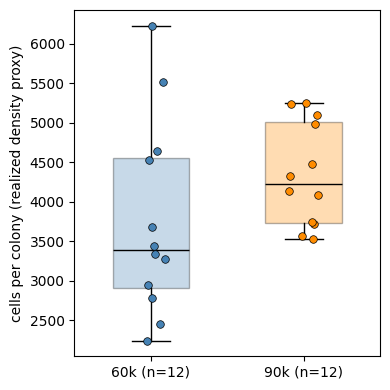

In [ ]:
# ============================================================
# Realized (not seeding-label) density per colony -- seeding density (60k/90k)
# did not correlate well with final density in practice, so treat the label
# as a grouping variable only; use actual final cell count as the real
# density covariate wherever density itself matters.
# ============================================================

cells_per_colony = data_D1.groupby(['condition', 'Colony']).size().rename('n_cells').reset_index()
print(cells_per_colony.sort_values('n_cells').to_string(index=False))

np.random.seed(0)  # reproducible jitter
fig, ax = plt.subplots(figsize=(4, 4))
conditions_plot = ['60k', '90k']
colors_plot = ['steelblue', 'darkorange']
data_by_cond = [cells_per_colony[cells_per_colony['condition'] == c]['n_cells'].to_numpy() for c in conditions_plot]

bp = ax.boxplot(data_by_cond, positions=range(1, len(conditions_plot) + 1),
                 tick_labels=[f'{c} (n={len(d)})' for c, d in zip(conditions_plot, data_by_cond)],
                 patch_artist=True, showfliers=False, widths=0.5)
for patch, color in zip(bp['boxes'], colors_plot):
    patch.set_facecolor(color)
    patch.set_alpha(0.3)
for median in bp['medians']:
    median.set_color('black')

for pos, vals, color in zip(range(1, len(conditions_plot) + 1), data_by_cond, colors_plot):
    jitter = np.random.uniform(-0.1, 0.1, size=len(vals))
    ax.scatter(np.full(len(vals), pos) + jitter, vals, color=color,
               edgecolors='black', linewidths=0.5, s=30, zorder=3)

ax.set_ylabel('cells per colony (realized density proxy)')
plt.tight_layout()
plt.show()


### Alignment of intensity distributions between experiments

In [75]:
# ============================================================
# Align expD1 (both conditions pooled) onto Exp20's B50 raw-unit scale, so
# thresh_20 (Exp20's manually-calibrated thresholds) can be applied
# meaningfully to expD1 data, and so self-CV accuracy (Q1) and cross-
# experiment prediction (Q2) both operate in comparable units.
#
# Runs on data_D1_core, BEFORE the pSMAD1 choice: the choice is made on self-CV
# performance, which needs aligned data, so alignment can't depend on it. All three
# pSMAD1 candidate columns are aligned here, each separately onto Exp20's 'pSMAD1';
# the other 4 signals and the genes don't depend on the choice at all.
#
# pSMAD1 candidates are cleaned by MASKING invalid values to NaN (NaN / negative /
# > RAW_CUTOFF / robust z > SIGNAL_OUTLIER_RZ), not by dropping rows -- which rows get
# dropped depends on which candidate wins, and that's decided later.
#
# Anchor population: ALL of expD1 (60k + 90k pooled) -- there is no B50-equivalent
# baseline in expD1 (see header). Signals: mean/std (fit_zscore_alignment). Genes:
# GENE_ALIGN_METHOD = 'two_peak' anchors the two tallest KDE peaks low->low, high->high
# where both are real peaks on both sides (relative prominence >= MIN_REL_PROMINENCE),
# otherwise falls back to fit_gene_alignment(anchor='ref_dominant'); 'ref_dominant'
# uses fit_gene_alignment for every marker.
#
# Outputs: data_D1_core_masked, data_D1_core_aligned, signal_align_D1_core (keys:
# 4 non-pSMAD1 signals + 3 candidates), gene_align_D1, gene_align_method_used.
# ============================================================
from scipy.signal import peak_prominences
importlib.reload(IIF);

GENE_ALIGN_METHOD = 'two_peak'   # or 'ref_dominant'
MIN_REL_PROMINENCE = 0.05        # two_peak: both anchor peaks must rise >= this (x tallest peak) above their dips

# --- mask invalid pSMAD1 candidate values ---
data_D1_core_masked = data_D1_core.copy()
for cand in psmad1_candidates:
    v = data_D1_core[cand]
    ok = v.notna() & (v >= 0) & (v <= RAW_CUTOFF)
    q = v[ok].quantile([0.25, 0.5, 0.75])
    ok &= ((v - q[0.5]) / (q[0.75] - q[0.25])) <= SIGNAL_OUTLIER_RZ
    data_D1_core_masked.loc[~ok, cand] = np.nan
    print(f"{cand}: {(~ok).sum()} values masked to NaN")

data_D1_core_all = data_D1_core_masked.assign(condition='ALL_D1')

# --- signals: 4 non-pSMAD1 signals, then each pSMAD1 candidate onto Exp20's 'pSMAD1' ---
signal_align_D1_core = IIF.fit_zscore_alignment(data_D1_core_all, exp_result_20.data, signals_core,
                                                 condition_self='ALL_D1', condition_ref='B50')
for cand in psmad1_candidates:
    cand_as_psmad1 = data_D1_core_all[[cand, 'condition']].rename(columns={cand: 'pSMAD1'})
    signal_align_D1_core[cand] = IIF.fit_zscore_alignment(
        cand_as_psmad1, exp_result_20.data, ['pSMAD1'], condition_self='ALL_D1', condition_ref='B50')['pSMAD1']

# --- genes ---
def two_tallest_peaks_linear(fit):
    """Linear-intensity positions of the two tallest KDE peaks in a fit_marker_distributions
    entry, sorted low -> high, plus each peak's prominence relative to the tallest peak
    (how far it rises above the dip beside it -- low for shoulders/tail bumps, unlike raw
    height). Returns (None, None) if only one peak was detected."""
    grid, density, offset = fit['grid'], fit['density'], fit['offset']
    idx = np.array([np.argmin(np.abs(grid - m)) for m in fit['all_modes']])
    if len(idx) < 2:
        return None, None
    top2 = np.sort(idx[np.argsort(density[idx])[-2:]])
    rel_prom = peak_prominences(density, top2)[0] / density.max()
    return 10**grid[top2] - offset, rel_prom

gene_align_D1 = IIF.fit_gene_alignment(data_D1_core_all, exp_result_20.data, common_genes,
                                       condition_self='ALL_D1', condition_ref='B50', anchor='ref_dominant')
gene_align_method_used = {marker: 'ref_dominant' for marker in common_genes}

if GENE_ALIGN_METHOD == 'two_peak':
    fits_self = IIF.fit_marker_distributions(data_D1_core_all, common_genes)
    fits_ref = IIF.fit_marker_distributions(data_B50_20, common_genes)
    for marker in common_genes:
        p_self, prom_self = two_tallest_peaks_linear(fits_self[marker])
        p_ref, prom_ref = two_tallest_peaks_linear(fits_ref[marker])
        if p_self is None or p_ref is None or min(prom_self.min(), prom_ref.min()) < MIN_REL_PROMINENCE:
            continue
        scale = (p_ref[1] - p_ref[0]) / (p_self[1] - p_self[0])
        gene_align_D1[marker] = (scale, p_ref[0] - scale * p_self[0])
        gene_align_method_used[marker] = 'two_peak'

# --- apply ---
data_D1_core_aligned = IIF.apply_alignment(data_D1_core_masked, signal_align_D1_core,
                                           signals_core + psmad1_candidates)
data_D1_core_aligned = IIF.apply_alignment(data_D1_core_aligned, gene_align_D1, common_genes)
# 'condition' is unchanged -- still the real '60k'/'90k' labels, only VALUES were transformed.

print(f"\ndata_D1_core: {len(data_D1_core)} cells")
for col in signals_core + psmad1_candidates:
    print(f"  {col:9s} scale={signal_align_D1_core[col][0]:.3f}")
for marker in common_genes:
    print(f"  {marker:9s} scale={gene_align_D1[marker][0]:.3f}  ({gene_align_method_used[marker]})")


pSMAD1_1: 1 values masked to NaN
pSMAD1_2: 2155 values masked to NaN
pSMAD1n5: 2521 values masked to NaN

data_D1_core: 97096 cells
  ncYAP     scale=0.450
  LEF1      scale=0.640
  ncSMAD23  scale=0.621
  cytopERK  scale=0.725
  pSMAD1_1  scale=2.405
  pSMAD1_2  scale=2.545
  pSMAD1n5  scale=3.721
  TFAP2C    scale=1.072  (ref_dominant)
  SOX17     scale=3.010  (ref_dominant)
  NANOG     scale=2.128  (ref_dominant)
  ISL1      scale=3.002  (two_peak)
  TBXT      scale=1.687  (ref_dominant)
  TBX6      scale=1.410  (ref_dominant)
  SOX2      scale=1.779  (two_peak)


OK: data_D1_core = 97096 cells ({'90k': 52082, '60k': 45014}), alignment consistent with it.

            type        method  scale   shift  % neg aligned                           flags
column                                                                                      
ncYAP     signal      mean/std  0.450    0.35           0.00                                
LEF1      signal      mean/std  0.640   69.98           0.00                                
ncSMAD23  signal      mean/std  0.621    0.29           0.00                                
cytopERK  signal      mean/std  0.725  439.36           0.00                                
pSMAD1_1  signal      mean/std  2.405 -398.03           2.57  >0.5% negative after alignment
pSMAD1_2  signal      mean/std  2.545 -642.85           5.00  >0.5% negative after alignment
pSMAD1n5  signal      mean/std  3.721 -227.31           0.18                                
TFAP2C      gene  ref_dominant  1.072  -62.85           0.07         

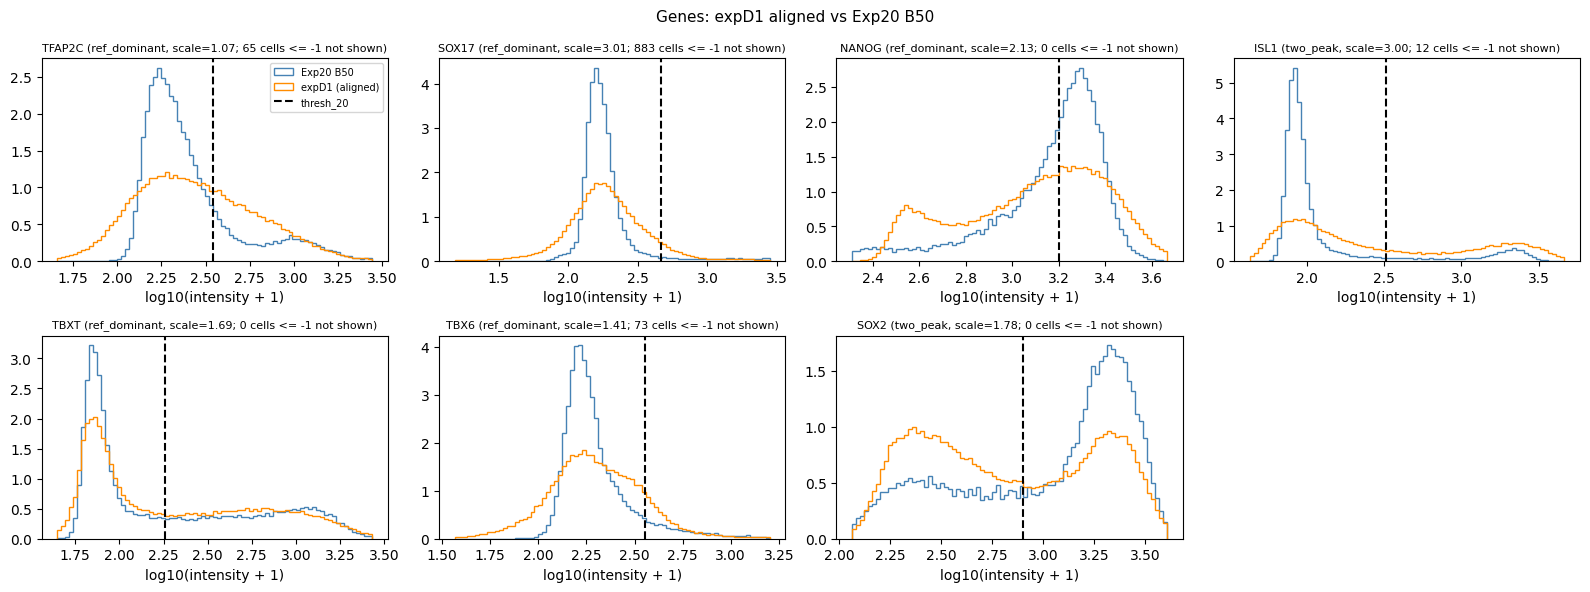

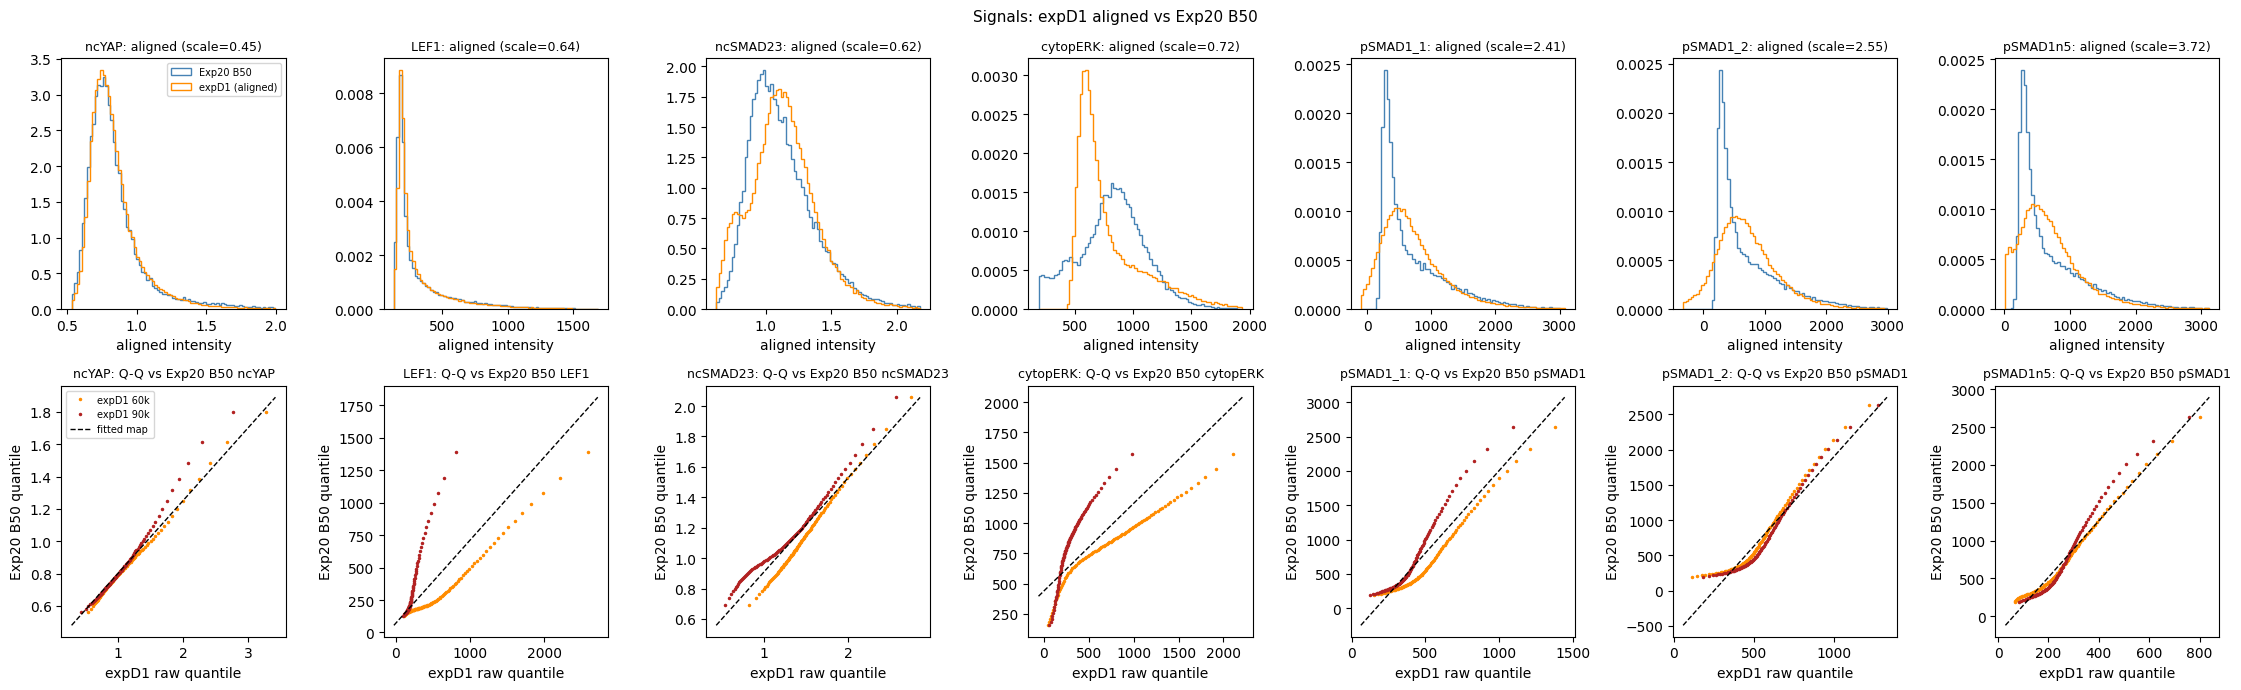

In [76]:
# ============================================================
# ALIGNMENT QC (signals AND gene markers) -- depends ONLY on the loading cells and
# 'Align expD1 (both conditions pooled) onto Exp20's B50 raw-unit scale'. Runs before,
# and independently of, the pSMAD1 choice: all three pSMAD1 candidates are shown.
#   1. Consistency checks: fails loudly if the alignment is stale relative to
#      data_D1_core (e.g. a cell re-run out of order).
#   2. Summary table: scale, shift, % of expD1 cells negative after alignment, flags.
#   3. Genes: aligned expD1 vs Exp20 B50, log10(x + 1) histograms on shared bins.
#   4. Signals (incl. each pSMAD1 candidate vs Exp20's pSMAD1): aligned histograms on
#      shared bins + Q-Q (raw expD1 60k/90k vs Exp20 B50, fitted map as the dashed line --
#      curvature = shape difference an affine map can't fix).
# ============================================================
LOAD_CELL = "'Load expD1 (disordered culture)'"
ALIGN_CELL = "'Align expD1 (both conditions pooled) onto Exp20's B50 raw-unit scale'"
signal_cols_qc = signals_core + psmad1_candidates

def ref_col(col):
    """Exp20 column a given expD1 column was aligned onto (pSMAD1 candidates -> 'pSMAD1')."""
    return 'pSMAD1' if col in psmad1_candidates else col

# --- 1. consistency checks ---
sig_q = data_D1_core[signals_core].quantile([0.25, 0.5, 0.75])
robust_z_max = ((data_D1_core[signals_core] - sig_q.loc[0.5]) / (sig_q.loc[0.75] - sig_q.loc[0.25])).max()
assert (robust_z_max <= SIGNAL_OUTLIER_RZ * 1.1).all(), \
    f"signal outliers still in data_D1_core (max robust z: {robust_z_max.round(1).to_dict()}) -- rerun {LOAD_CELL}, then {ALIGN_CELL}"

assert len(data_D1_core_masked) == len(data_D1_core) and len(data_D1_core_aligned) == len(data_D1_core) \
       and np.allclose(data_D1_core_masked[signals_core], data_D1_core[signals_core]), \
    f"alignment outputs don't match the current data_D1_core ({len(data_D1_core)} cells) -- rerun {ALIGN_CELL}"

signal_refit = IIF.fit_zscore_alignment(data_D1_core_masked.assign(condition='ALL_D1'), exp_result_20.data,
                                        signals_core, condition_self='ALL_D1', condition_ref='B50')
stale_sig = [s for s in signals_core if not np.allclose(signal_refit[s], signal_align_D1_core[s])]
assert not stale_sig, f"signal alignment not fit on the current data_D1_core ({stale_sig}) -- rerun {ALIGN_CELL}"

recomputed = IIF.apply_alignment(IIF.apply_alignment(data_D1_core_masked, signal_align_D1_core, signal_cols_qc),
                                 gene_align_D1, common_genes)
stale_cols = [c for c in signal_cols_qc + common_genes
              if not np.allclose(recomputed[c], data_D1_core_aligned[c], equal_nan=True)]
assert not stale_cols, f"data_D1_core_aligned doesn't match current alignment params ({stale_cols}) -- rerun {ALIGN_CELL}"

print(f"OK: data_D1_core = {len(data_D1_core)} cells ({data_D1_core['condition'].value_counts().to_dict()}), "
      f"alignment consistent with it.\n")

# --- 2. summary table ---
rows = []
for col in signal_cols_qc + common_genes:
    is_gene = col in common_genes
    scale, shift = (gene_align_D1 if is_gene else signal_align_D1_core)[col]
    flags = []
    if scale < 0.2 or scale > 4.5:
        flags.append('scale extreme / near optimizer bound')
    pct_neg = (data_D1_core_aligned[col] < 0).mean() * 100
    if pct_neg > 0.5:
        flags.append('>0.5% negative after alignment')
    rows.append({'column': col, 'type': 'gene' if is_gene else 'signal',
                 'method': gene_align_method_used[col] if is_gene else 'mean/std',
                 'scale': round(scale, 3), 'shift': round(shift, 2),
                 '% neg aligned': round(pct_neg, 2), 'flags': '; '.join(flags)})
print(pd.DataFrame(rows).set_index('column').to_string())

# --- 3. genes: log-space histograms, shared bins ---
eps = 1.0
ncols = 4
nrows = int(np.ceil(len(common_genes) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = np.atleast_1d(axes).ravel()
for i, marker in enumerate(common_genes):
    ax = axes[i]
    raw_20, raw_D1a = data_B50_20[marker].to_numpy(), data_D1_core_aligned[marker].to_numpy()
    v20 = np.log10(raw_20[raw_20 > -eps] + eps)
    vD1a = np.log10(raw_D1a[raw_D1a > -eps] + eps)
    bins = np.linspace(*np.percentile(np.concatenate([v20, vD1a]), [0.5, 99.5]), 80)
    ax.hist(v20, bins=bins, density=True, histtype='step', color='steelblue', label='Exp20 B50')
    ax.hist(vD1a, bins=bins, density=True, histtype='step', color='darkorange', label='expD1 (aligned)')
    ax.axvline(np.log10(thresh_20[marker] + eps), color='black', linestyle='--', label='thresh_20')
    ax.set_title(f'{marker} ({gene_align_method_used[marker]}, scale={gene_align_D1[marker][0]:.2f}; '
                 f'{(raw_D1a <= -eps).sum()} cells <= -{eps:g} not shown)', fontsize=8)
    ax.set_xlabel(f'log10(intensity + {eps:g})')
    if i == 0:
        ax.legend(fontsize=7)
for j in range(len(common_genes), len(axes)):
    axes[j].axis('off')
fig.suptitle('Genes: expD1 aligned vs Exp20 B50', fontsize=11)
plt.tight_layout()
plt.show()

# --- 4. signals: shared-bin histograms + Q-Q ---
quantile_levels = np.linspace(0.01, 0.99, 99)
fig, axes = plt.subplots(2, len(signal_cols_qc), figsize=(3.2 * len(signal_cols_qc), 7))
for j, col in enumerate(signal_cols_qc):
    ref = data_B50_20[ref_col(col)].dropna().to_numpy()
    d1a = data_D1_core_aligned[col].dropna().to_numpy()
    scale, shift = signal_align_D1_core[col]

    ax = axes[0, j]
    bins = np.linspace(*np.percentile(np.concatenate([ref, d1a]), [0.5, 99.5]), 80)
    ax.hist(ref, bins=bins, density=True, histtype='step', color='steelblue', label='Exp20 B50')
    ax.hist(d1a, bins=bins, density=True, histtype='step', color='darkorange', label='expD1 (aligned)')
    ax.set_title(f'{col}: aligned (scale={scale:.2f})', fontsize=9)
    ax.set_xlabel('aligned intensity')
    if j == 0:
        ax.legend(fontsize=7)

    ax = axes[1, j]
    q_ref = np.quantile(ref, quantile_levels)
    for cond, color in [('60k', 'darkorange'), ('90k', 'firebrick')]:
        v = data_D1_core_masked.loc[data_D1_core_masked['condition'] == cond, col].dropna().to_numpy()
        ax.plot(np.quantile(v, quantile_levels), q_ref, '.', ms=3, color=color, label=f'expD1 {cond}')
    x_line = np.array(ax.get_xlim())
    ax.plot(x_line, scale * x_line + shift, 'k--', lw=1, label='fitted map')
    ax.set_title(f'{col}: Q-Q vs Exp20 B50 {ref_col(col)}', fontsize=9)
    ax.set_xlabel('expD1 raw quantile')
    ax.set_ylabel('Exp20 B50 quantile')
    if j == 0:
        ax.legend(fontsize=7)
fig.suptitle('Signals: expD1 aligned vs Exp20 B50', fontsize=11)
plt.tight_layout()
plt.show()


TFAP2C+ fraction per position (thresh_20=349):
condition    60k    90k
Colony                 
1          0.346    NaN
2          0.552    NaN
3          0.650    NaN
4          0.584    NaN
5          0.638    NaN
6          0.674    NaN
7          0.439    NaN
8          0.349    NaN
9          0.586    NaN
10         0.691    NaN
11         0.597    NaN
12         0.537    NaN
13           NaN  0.160
14           NaN  0.214
15           NaN  0.328
16           NaN  0.140
17           NaN  0.188
18           NaN  0.371
19           NaN  0.271
20           NaN  0.159
21           NaN  0.232
22           NaN  0.332
23           NaN  0.245
24           NaN  0.260


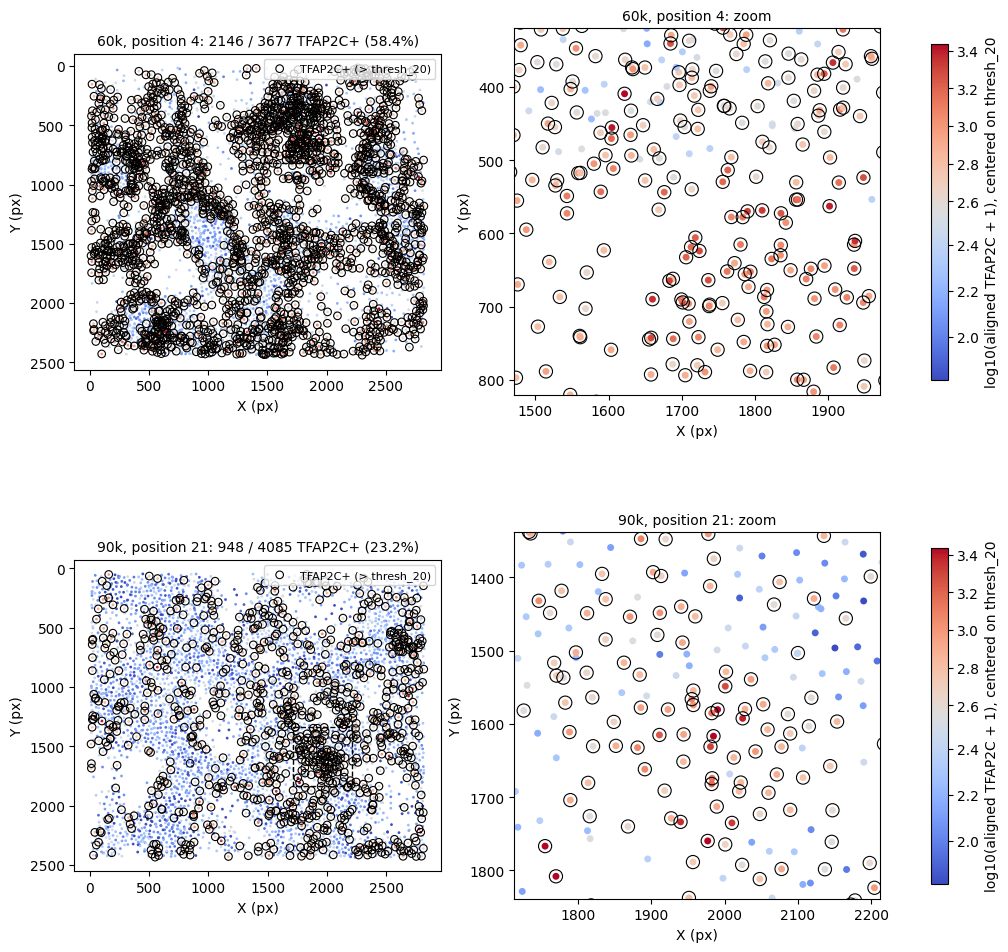

In [62]:
# ============================================================
# SOX17 threshold sanity check in space: for one representative position per condition
# (the position whose SOX17+ fraction is closest to that condition's median), plot cell
# positions colored by aligned SOX17 intensity (log10, diverging colormap centered on
# thresh_20: red above, blue below), with cells called positive by thresh_20 circled.
# Left: full field; right: zoom on the densest cluster of positive cells, where
# individual calls can actually be judged by eye.
# ============================================================
from matplotlib.colors import TwoSlopeNorm

marker = 'TFAP2C'
data_spatial = data_D1_aligned          # swap for data_D1_aligned_2peak to check that alignment instead
zoom_half_width = 250                   # pixels, half-width of the zoomed box
eps = 1.0

is_pos = data_spatial[marker] > thresh_20[marker]
frac_pos = is_pos.groupby([data_spatial['condition'], data_spatial['Colony']]).mean()
print(f"{marker}+ fraction per position (thresh_20={thresh_20[marker]:.0f}):")
print(frac_pos.unstack(0).round(3).to_string())

log_int = np.log10(data_spatial[marker].clip(lower=0) + eps)
log_thresh = np.log10(thresh_20[marker] + eps)
vmin, vmax = np.percentile(log_int, [2, 99.5])
norm = TwoSlopeNorm(vcenter=log_thresh, vmin=min(vmin, log_thresh - 0.1), vmax=max(vmax, log_thresh + 0.1))

def pick_representative_position(cond):
    """Colony (imaging position) in `cond` whose marker+ fraction is closest to the
    median fraction across that condition's positions."""
    f = frac_pos.loc[cond]
    return (f - f.median()).abs().idxmin()

def densest_positive_center(x, y, pos_mask, half_width):
    """(x, y) center of the zoom box that contains the most positive cells, searched
    over a coarse grid of candidate centers; falls back to the field center when no
    cell is positive."""
    if pos_mask.sum() == 0:
        return x.mean(), y.mean()
    xp, yp = x[pos_mask], y[pos_mask]
    cx_grid = np.linspace(x.min() + half_width, x.max() - half_width, 20)
    cy_grid = np.linspace(y.min() + half_width, y.max() - half_width, 20)
    counts = [((np.abs(xp - cx) < half_width) & (np.abs(yp - cy) < half_width)).sum()
              for cx in cx_grid for cy in cy_grid]
    best = int(np.argmax(counts))
    return cx_grid[best // len(cy_grid)], cy_grid[best % len(cy_grid)]

conditions_spatial = ['60k', '90k']
fig, axes = plt.subplots(len(conditions_spatial), 2, figsize=(13, 6 * len(conditions_spatial)))
for row, cond in enumerate(conditions_spatial):
    col_id = pick_representative_position(cond)
    sel = (data_spatial['condition'] == cond) & (data_spatial['Colony'] == col_id)
    x, y = data_spatial.loc[sel, 'X'].to_numpy(), data_spatial.loc[sel, 'Y'].to_numpy()
    c, pos = log_int[sel].to_numpy(), is_pos[sel].to_numpy()
    cx, cy = densest_positive_center(x, y, pos, zoom_half_width)

    for ax, zoomed in [(axes[row, 0], False), (axes[row, 1], True)]:
        dot, ring = (4, 30) if not zoomed else (25, 90)
        sc = ax.scatter(x, y, c=c, s=dot, cmap='coolwarm', norm=norm, linewidths=0)
        ax.scatter(x[pos], y[pos], s=ring, facecolors='none', edgecolors='black', linewidths=0.8,
                   label=f'{marker}+ (> thresh_20)')
        ax.set_aspect('equal')
        ax.invert_yaxis()  # image convention: y increases downward
        if zoomed:
            ax.set_xlim(cx - zoom_half_width, cx + zoom_half_width)
            ax.set_ylim(cy + zoom_half_width, cy - zoom_half_width)
            ax.set_title(f'{cond}, position {col_id}: zoom', fontsize=10)
        else:
            ax.add_patch(plt.Rectangle((cx - zoom_half_width, cy - zoom_half_width),
                                       2 * zoom_half_width, 2 * zoom_half_width,
                                       fill=False, edgecolor='black', linestyle='--'))
            ax.set_title(f'{cond}, position {col_id}: {pos.sum()} / {len(pos)} {marker}+ '
                         f'({pos.mean():.1%})', fontsize=10)
            ax.legend(fontsize=8, loc='upper right')
        ax.set_xlabel('X (px)')
        ax.set_ylabel('Y (px)')
    fig.colorbar(sc, ax=axes[row, :], shrink=0.8, label=f'log10(aligned {marker} + {eps:g}), centered on thresh_20')

plt.show()


### Select best pSMAD1 stain


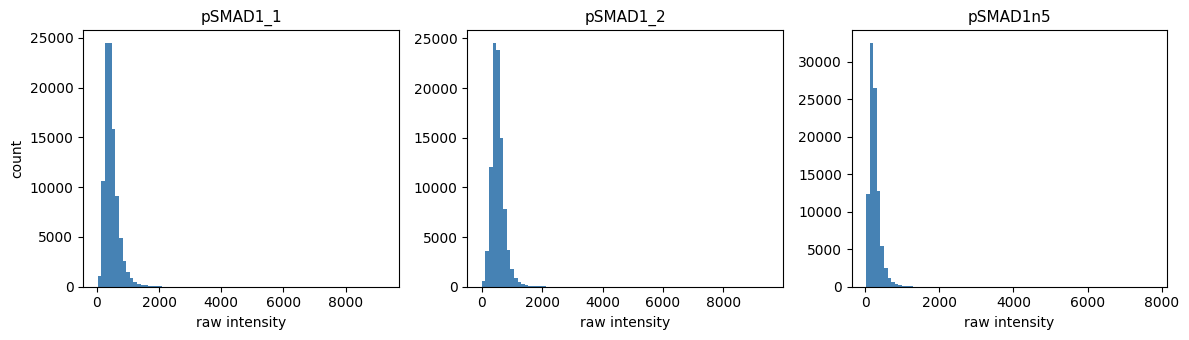

In [77]:
# ============================================================
# pSMAD1 candidate comparison, part 1: signal quality (NaN/junk fraction,
# distribution shape). Context: pSMAD1_1=rd3, pSMAD1_2=rd6 re-stain
# (consensus: less grainy, but more junk cells), pSMAD1n5=a different
# pSMAD1/5 antibody tried in rd7, untested elsewhere.
#
# Stores per-candidate numbers in psmad1_quality so the summary cell after
# the self-CV comparison can print one clean combined table, instead of you
# having to scroll back through this cell's (and the self-CV cell's)
# progress/warning output to find them again.
# ============================================================

psmad1_quality = {}

fig, axes = plt.subplots(1, len(psmad1_candidates), figsize=(4 * len(psmad1_candidates), 3.5))
for ax, cand in zip(axes, psmad1_candidates):
    vals_all = data_D1_core[cand]
    n_nan = vals_all.isna().sum()
    n_neg = (vals_all < 0).sum()
    valid = vals_all.dropna()
    valid = valid[valid >= 0]
    n_junk = (valid > RAW_CUTOFF).sum()
    n_clean = len(valid) - n_junk

    psmad1_quality[cand] = {
        'n_nan': n_nan, 'nan_pct': n_nan / len(vals_all) * 100,
        'n_junk': n_junk, 'junk_pct': n_junk / max(len(valid), 1) * 100,
        'n_clean': n_clean,
    }

    clean_vals = valid[valid <= RAW_CUTOFF]
    ax.hist(clean_vals, bins=80, color='steelblue')
    ax.set_title(cand, fontsize=11)
    ax.set_xlabel('raw intensity')

axes[0].set_ylabel('count')
plt.tight_layout()
plt.show()

[pSMAD1 candidate pSMAD1_1] Run 0/3
[pSMAD1 candidate pSMAD1_1]   col: 1
[pSMAD1 candidate pSMAD1_1]   col: 2
[pSMAD1 candidate pSMAD1_1]   col: 3
[pSMAD1 candidate pSMAD1_1]   col: 4
[pSMAD1 candidate pSMAD1_1]   col: 5
[pSMAD1 candidate pSMAD1_1]   col: 6
[pSMAD1 candidate pSMAD1_1]   col: 7
[pSMAD1 candidate pSMAD1_1]   col: 8
[pSMAD1 candidate pSMAD1_1]   col: 9
[pSMAD1 candidate pSMAD1_1]   col: 10
[pSMAD1 candidate pSMAD1_1]   col: 11
[pSMAD1 candidate pSMAD1_1]   col: 12
[pSMAD1 candidate pSMAD1_1]   col: 13
[pSMAD1 candidate pSMAD1_1]   col: 14
[pSMAD1 candidate pSMAD1_1]   col: 15
[pSMAD1 candidate pSMAD1_1]   col: 16
[pSMAD1 candidate pSMAD1_1]   col: 17
[pSMAD1 candidate pSMAD1_1]   col: 18
[pSMAD1 candidate pSMAD1_1]   col: 19
[pSMAD1 candidate pSMAD1_1]   col: 20
[pSMAD1 candidate pSMAD1_1]   col: 21
[pSMAD1 candidate pSMAD1_1]   col: 22
[pSMAD1 candidate pSMAD1_1]   col: 23
[pSMAD1 candidate pSMAD1_1]   col: 24
[pSMAD1 candidate pSMAD1_1] Elapsed time: 108.4 seconds
[pSMA

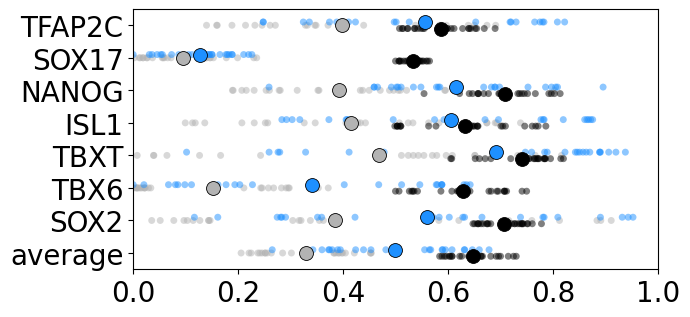

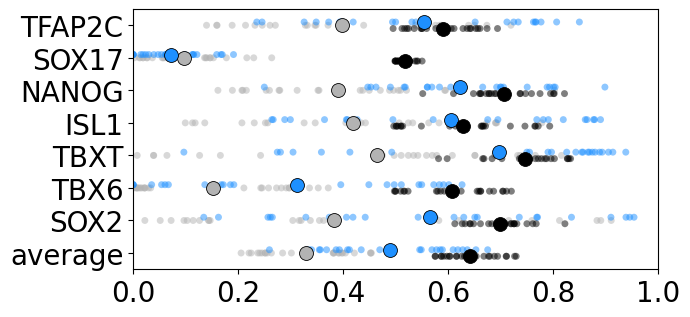

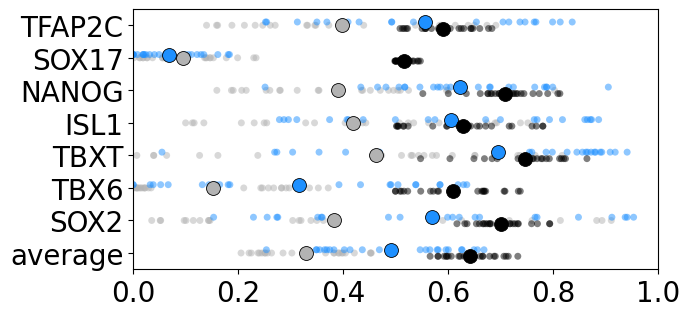

In [78]:
# ============================================================
# pSMAD1 candidate comparison, part 2: downstream self-CV prediction accuracy.
# For each candidate, take its column from data_D1_core_aligned (aligned in
# 'Align expD1 (both conditions pooled) onto Exp20's B50 raw-unit scale', same
# signal/gene alignment as everything downstream), rename it to 'pSMAD1', drop cells
# where it's NaN/masked, and run the same leave-one-colony-out self-CV pipeline as
# Q1, pooled across both density conditions (60k+90k) for a single number per
# candidate. RECOMPUTE_PSMAD1: retrain instead of loading cached runs -- needed after
# any change to the alignment (e.g. the signal outlier filter).
# ============================================================

RECOMPUTE_PSMAD1 = True
labels_perf = common_genes + ['marker_avg']  # also (re)defined identically in the Q1 cell further down

out_dir_psmad1 = dataDir + '/expD1_VIB/psmad1_comparison'
psmad1_results = {}

for cand in psmad1_candidates:
    data_cand_aligned = data_D1_core_aligned[data_D1_core_aligned[cand].notna()].copy()
    data_cand_aligned['pSMAD1'] = data_cand_aligned[cand]

    IIF.run_vib_self(data_cand_aligned, signals, common_genes, hyperparam, N_run=3,
                     out_dir=out_dir_psmad1, out_prefix=f'selfCV_{cand}', label=f'pSMAD1 candidate {cand}',
                     recompute=RECOMPUTE_PSMAD1)
    pred_cand = IIF.load_vib_self(data_cand_aligned, signals, common_genes, hyperparam, N_run=3,
                                  out_dir=out_dir_psmad1, out_prefix=f'selfCV_{cand}')['avg']
    perfold_cand = IIF.compute_marker_performance_perfold(
        data_cand_aligned, pred_cand, data_cand_aligned['Colony'].to_numpy(), common_genes, thresh_20)
    perfold_cand = IIF.add_group_avg(perfold_cand, ['f1_rand', 'f1', 'balanced_accuracy'], group_col='gene', avg_label='marker_avg')
    psmad1_results[cand] = perfold_cand

    avg_row = perfold_cand[perfold_cand['gene'] == 'marker_avg']
    print(f"{cand:12s}  n={len(data_cand_aligned):6d}  F1={avg_row['f1'].mean():.3f}  "
          f"balanced_acc={avg_row['balanced_accuracy'].mean():.3f}")

for cand, perfold_cand in psmad1_results.items():
    IIF.plot_category_performance_perfold(
        perfold_cand, labels_perf,
        dataDir + f'/expD1_VIB/psmad1_comparison/perfold_{cand}.pdf',
        group_col='gene', tick_labels=labels_perf[:-1] + ['average'])


In [79]:
# ============================================================
# pSMAD1 candidate comparison: clean summary table, pulling together
# psmad1_quality (signal quality) and psmad1_results (self-CV accuracy) --
# everything needed to set WINNING_PSMAD1 below, without scrolling back
# through the training progress/warning output of the two cells above.
# ============================================================

summary_rows = []
for cand in psmad1_candidates:
    q = psmad1_quality[cand]
    avg_row = psmad1_results[cand][psmad1_results[cand]['gene'] == 'marker_avg']
    summary_rows.append({
        'candidate': cand,
        'nan_%': round(q['nan_pct'], 1),
        'junk_%': round(q['junk_pct'], 1),
        'n_clean': q['n_clean'],
        'F1': round(avg_row['f1'].mean(), 3),
        'balanced_acc': round(avg_row['balanced_accuracy'].mean(), 3),
    })

psmad1_summary = pd.DataFrame(summary_rows).set_index('candidate')
print(psmad1_summary.to_string())

           nan_%  junk_%  n_clean     F1  balanced_acc
candidate                                             
pSMAD1_1     0.0     0.0    97096  0.500         0.648
pSMAD1_2     2.2     0.0    94948  0.490         0.643
pSMAD1n5     2.6     0.0    94579  0.491         0.643


## Analysis

In [82]:
# ============================================================
# Resolve pSMAD1: commit to WINNING_PSMAD1 = 'pSMAD1_1'. Chosen in the pSMAD1
# candidate comparison (appendix): after the alignment fixes, all three candidates
# score within ~0.01 F1 / ~0.005 balanced accuracy of each other (pSMAD1_1 marginally
# best), and pSMAD1_1 is the only one with complete data -- pSMAD1_2 / pSMAD1n5 are
# missing most of positions 10-11. No fitting here -- just selects the winning
# candidate's already-aligned column; doesn't depend on the comparison cells.
# Outputs: data_D1 (raw units), data_D1_aligned (Exp20 units), data_D1_all (data_D1
# relabeled 'ALL_D1', for run_vib_cross_experiment), signal_align_D1 (keyed by `signals`).
# ============================================================

WINNING_PSMAD1 = 'pSMAD1_1'

keep_winner = data_D1_core_masked[WINNING_PSMAD1].notna()

def resolve_psmad1(df):
    """Rows where the winning candidate is valid, with it copied to 'pSMAD1' and all
    candidate columns dropped."""
    out = df[keep_winner].copy()
    out['pSMAD1'] = out[WINNING_PSMAD1]
    return out.drop(columns=psmad1_candidates).reset_index(drop=True)

data_D1 = resolve_psmad1(data_D1_core_masked)
data_D1_aligned = resolve_psmad1(data_D1_core_aligned)
data_D1_all = data_D1.assign(condition='ALL_D1')
signal_align_D1 = {s: signal_align_D1_core[s] for s in signals_core}
signal_align_D1['pSMAD1'] = signal_align_D1_core[WINNING_PSMAD1]

print(f"Resolved pSMAD1 -> {WINNING_PSMAD1}. expD1: {len(data_D1)} cells "
      f"({(~keep_winner).sum()} dropped for invalid {WINNING_PSMAD1}), "
      f"conditions: {data_D1['condition'].value_counts().to_dict()}")

Resolved pSMAD1 -> pSMAD1_1. expD1: 97095 cells (1 dropped for invalid pSMAD1_1), conditions: {'90k': 52081, '60k': 45014}


In [87]:
# ============================================================
# CV folds for expD1: balanced, mixed TRIPLETS of positions (not single positions).
# Disordered-culture positions are patchy in fate composition (e.g. SOX17+ 0.2-24% per
# position, TBX6+ ~27% at 60k vs ~1.5% at 90k), so single-position folds give test sets
# with very different fate distributions. In micropatterned colonies every colony has
# the full fate pattern, so folds there always have a similar distribution; to make
# expD1's performance evaluation comparable, folds here are groups of 3 whole positions
# (2 x 60k + 1 x 90k, or 1 x 60k + 2 x 90k; 8 folds total) chosen so their marker-positive
# fractions (under thresh_20) and cell counts are as similar as possible. Whole positions
# stay together, so neighbouring cells never straddle train/test.
#
# Search: hill-climbing over swaps of same-condition positions between triplets, from
# N_RESTARTS seeded random starts (deterministic: same data -> same triplets).
#
# fate_fingerprint: short hash of every cell's marker +/- calls (thresh_20 on
# data_D1_aligned, plus which cells are present). Any change in alignment or filtering
# that moves a fate call changes it; Q1 puts it in its cache name, so cached models are
# only reused when the fate calls (and therefore the triplets) are unchanged.
#
# Outputs: data_D1_aligned['fold'], fold_triplets, fate_fingerprint.
# ============================================================
import hashlib

N_RESTARTS = 300
TRIPLET_LAYOUT = [(2, 1)] * 4 + [(1, 2)] * 4   # (n 60k positions, n 90k positions) per triplet

marker_pos = pd.DataFrame({m: data_D1_aligned[m] > thresh_20[m] for m in common_genes})
fate_fingerprint = hashlib.md5(
    marker_pos.to_numpy().tobytes()
    + data_D1_aligned[['condition', 'Colony', 'X', 'Y']].to_csv(index=False).encode()).hexdigest()[:8]

position_keys = sorted(set(zip(data_D1_aligned['condition'], data_D1_aligned['Colony'])), key=lambda k: k[1])
key_series = pd.Series(list(zip(data_D1_aligned['condition'], data_D1_aligned['Colony'])), index=data_D1_aligned.index)
n_cells = np.array([(key_series == k).sum() for k in position_keys], float)
n_pos = np.array([marker_pos[key_series == k].sum().to_numpy() for k in position_keys], float)
overall_frac = n_pos.sum(0) / n_cells.sum()
cond_of = np.array([k[0] for k in position_keys])

def grouping_cost(groups):
    """Imbalance of a grouping (list of index arrays into position_keys): relative variance
    across groups of each marker's positive fraction (so rare markers count as much as
    common ones), summed over markers, plus the relative variance of cell counts."""
    ng = np.array([n_cells[g].sum() for g in groups])
    fg = np.array([n_pos[g].sum(0) / n_cells[g].sum() for g in groups])
    return (fg.var(0) / overall_frac**2).sum() + ng.var() / ng.mean()**2

def random_triplets(rng):
    """Random assignment of 60k / 90k positions into TRIPLET_LAYOUT."""
    idx60 = rng.permutation(np.where(cond_of == '60k')[0])
    idx90 = rng.permutation(np.where(cond_of == '90k')[0])
    groups, i, j = [], 0, 0
    for s60, s90 in TRIPLET_LAYOUT:
        groups.append(np.concatenate([idx60[i:i + s60], idx90[j:j + s90]]))
        i, j = i + s60, j + s90
    return groups

def balanced_triplets(n_restarts, seed=0):
    """Lowest-cost triplet grouping found by hill-climbing (swapping same-condition
    positions between triplets until no swap helps) from n_restarts seeded random starts."""
    rng = np.random.default_rng(seed)
    best, best_cost = None, np.inf
    for _ in range(n_restarts):
        groups = random_triplets(rng)
        cost = grouping_cost(groups)
        improved = True
        while improved:
            improved = False
            for gi in range(len(groups)):
                for gj in range(gi + 1, len(groups)):
                    for a in range(len(groups[gi])):
                        for b in range(len(groups[gj])):
                            if cond_of[groups[gi][a]] != cond_of[groups[gj][b]]:
                                continue
                            groups[gi][a], groups[gj][b] = groups[gj][b], groups[gi][a]
                            new_cost = grouping_cost(groups)
                            if new_cost < cost - 1e-12:
                                cost, improved = new_cost, True
                            else:
                                groups[gi][a], groups[gj][b] = groups[gj][b], groups[gi][a]
        if cost < best_cost:
            best, best_cost = [g.copy() for g in groups], cost
    return best, best_cost

groups, cost = balanced_triplets(N_RESTARTS)
fold_triplets = {f: sorted(position_keys[i] for i in g) for f, g in enumerate(groups, start=1)}
fold_of_position = {k: f for f, keys in fold_triplets.items() for k in keys}
data_D1_aligned['fold'] = key_series.map(fold_of_position).to_numpy()

print(f"fate_fingerprint = {fate_fingerprint}   imbalance cost = {cost:.3f}")
summary = pd.DataFrame({
    'positions': {f: ', '.join(f'{p} ({c})' for c, p in keys) for f, keys in fold_triplets.items()},
    'n_cells': data_D1_aligned.groupby('fold').size(),
    **{m: marker_pos[m].groupby(data_D1_aligned['fold']).mean().round(3) for m in common_genes}})
print(summary.to_string())


fate_fingerprint = af0f9c5a   imbalance cost = 0.106
                     positions  n_cells  TFAP2C  SOX17  NANOG   ISL1   TBXT   TBX6   SOX2
1  6 (60k), 12 (60k), 13 (90k)    11365   0.403  0.092  0.378  0.392  0.354  0.152  0.499
2   5 (60k), 7 (60k), 16 (90k)    12700   0.362  0.089  0.387  0.359  0.395  0.155  0.502
3  1 (60k), 10 (60k), 23 (90k)    12026   0.381  0.079  0.507  0.385  0.661  0.166  0.430
4  8 (60k), 11 (60k), 20 (90k)    12941   0.323  0.090  0.397  0.321  0.464  0.161  0.501
5  4 (60k), 19 (90k), 22 (90k)    11665   0.388  0.072  0.430  0.397  0.441  0.108  0.366
6  9 (60k), 15 (90k), 17 (90k)    11719   0.351  0.091  0.434  0.381  0.408  0.109  0.397
7  2 (60k), 14 (90k), 18 (90k)    13436   0.374  0.078  0.424  0.374  0.426  0.133  0.459
8  3 (60k), 21 (90k), 24 (90k)    11243   0.369  0.073  0.399  0.398  0.451  0.123  0.361


In [88]:
# ============================================================
# Q1: self (held-out) prediction accuracy per marker for expD1 (in Exp20-aligned units,
# so thresh_20 applies meaningfully), compared against Exp20 B50's own self-CV accuracy
# -- recomputed fresh here (same hyperparam/convention) for a fair side-by-side, rather
# than reusing a possibly-differently-configured cached run from another notebook.
#
# Folds: Exp20 B50 = its 6 colonies (leave-one-colony-out). expD1 = the 8 balanced
# mixed triplets of positions (see 'CV folds for expD1'): ONE model per fold, trained
# on 60k + 90k pooled. The triplets are deliberately balanced in fate composition, to
# make expD1's evaluation comparable to the micropatterned one: every micropattern
# colony contains the full fate pattern, so its folds always have a similar fate
# distribution. The fold-to-fold spread therefore reflects model stability, not how
# much performance varies between regions of the disordered culture.
#
# Scores: 'D1 pooled' per triplet (8 dots). 'D1 60k (total)' / 'D1 90k (total)': all
# held-out predictions for that condition's cells scored at once (one value per marker,
# no per-fold spread -- a condition's share of a triplet is only 1-2 positions).
#
# Matches fig2n's established convention: train on ALL cells (unfiltered -- every cell
# is useful signal for training regardless of how clean its fate call is), but only
# SCORE accuracy on cells whose measured fate isn't 'other' (ambiguous ground truth
# shouldn't penalize the model), applied identically to Exp20 B50 and expD1.
#
# Caching: expD1 runs are cached under selfCV_triplets_<fate_fingerprint>, so they're
# retrained automatically whenever the fate calls change (alignment / filtering), and
# loaded otherwise. Exp20 B50 is unaffected by expD1's alignment and always loaded.
# ============================================================

labels_perf = common_genes + ['marker_avg']
perfold_by_source = {}
out_dir_ref = dataDir + '/DisorderedComparison_VIB'
out_dir_D1 = dataDir + '/expD1_VIB'

def scored_subset(data_cond, thresh):
    """Rows of data_cond whose measured fate call (return_fates with `thresh`) isn't 'other'."""
    fates_cond, _ = IIF.return_fates(data_cond, thresh=thresh)
    keep = fates_cond != 'other'
    return data_cond[keep]

def perfold_scores(data_scored, pred, fold_col):
    """Marker performance of `pred` on `data_scored`, one fold per unique value of
    data_scored[fold_col], plus the per-fold marker average."""
    perfold = IIF.compute_marker_performance_perfold(
        data_scored, pred.loc[data_scored.index], data_scored[fold_col].to_numpy(), common_genes, thresh_20)
    return IIF.add_group_avg(perfold, ['f1_rand', 'f1', 'balanced_accuracy'], group_col='gene', avg_label='marker_avg')

def total_scores(data_scored, pred):
    """Marker performance of `pred` on all of `data_scored` at once (a single 'fold'),
    plus the marker average."""
    return perfold_scores(data_scored.assign(_all='all'), pred, '_all')

# Exp20 B50 (reference, micropattern)
IIF.run_vib_self(data_B50_20, signals, common_genes, hyperparam, N_run=3,
                 out_dir=out_dir_ref, out_prefix='selfB50_20', label='Exp20 B50')
pred_selfB50_20 = IIF.load_vib_self(data_B50_20, signals, common_genes, hyperparam, N_run=3,
                                    out_dir=out_dir_ref, out_prefix='selfB50_20')['avg']
perfold_by_source['Exp20 B50'] = perfold_scores(scored_subset(data_B50_20, thresh_20), pred_selfB50_20, 'Colony')

# expD1: one model per balanced triplet fold (run_vib_self folds on 'Colony')
data_D1_folds = data_D1_aligned.assign(Colony=data_D1_aligned['fold'])
prefix_D1 = f'selfCV_triplets_{fate_fingerprint}'
IIF.run_vib_self(data_D1_folds, signals, common_genes, hyperparam, N_run=3,
                 out_dir=out_dir_D1, out_prefix=prefix_D1, label='D1 triplets')
pred_self_D1 = IIF.load_vib_self(data_D1_folds, signals, common_genes, hyperparam, N_run=3,
                                 out_dir=out_dir_D1, out_prefix=prefix_D1)['avg']

data_D1_scored = scored_subset(data_D1_aligned, thresh_20)
perfold_by_source['D1 pooled'] = perfold_scores(data_D1_scored, pred_self_D1, 'fold')
for cond in ['60k', '90k']:
    perfold_by_source[f'D1 {cond} (total)'] = total_scores(
        data_D1_scored[data_D1_scored['condition'] == cond], pred_self_D1)

for src_label, perfold_df in perfold_by_source.items():
    avg_row = perfold_df[perfold_df['gene'] == 'marker_avg']
    print(f"{src_label:16s}  F1={avg_row['f1'].mean():.3f}  balanced_acc={avg_row['balanced_accuracy'].mean():.3f}")


[Exp20 B50] Run 0/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding//DisorderedComparison_VIB/selfB50_20_run0.csv
[Exp20 B50] Run 1/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding//DisorderedComparison_VIB/selfB50_20_run1.csv
[Exp20 B50] Run 2/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding//DisorderedComparison_VIB/selfB50_20_run2.csv
Run 0/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding//DisorderedComparison_VIB/selfB50_20_run0.csv
Run 1/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding//DisorderedComparison_VIB/selfB50_20_run1.csv
Run 2/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding//DisorderedComparison_VIB/selfB50_20_run2.csv
[D1 triplets] Run 0/3
[D1 triplets]   col: 1
[D1 triplets]   col: 2
[D1 triplets]   col: 3
[D1 triplets]   col: 4
[D1 triplets]   col: 5
[D1 triplets]   col: 6
[D1 triplets]   col: 7
[D1 triplets]   col: 8
[D1 triplets] Elapsed time: 35.9

Exp20 B50
marker_avg | f1_rand = 0.301
marker_avg | f1 = 0.728
marker_avg | balanced_accuracy = 0.820
D1 pooled
marker_avg | f1_rand = 0.330
marker_avg | f1 = 0.586
marker_avg | balanced_accuracy = 0.681
D1 60k (total)
marker_avg | f1_rand = 0.417
marker_avg | f1 = 0.633
marker_avg | balanced_accuracy = 0.678
D1 90k (total)
marker_avg | f1_rand = 0.253
marker_avg | f1 = 0.458
marker_avg | balanced_accuracy = 0.649


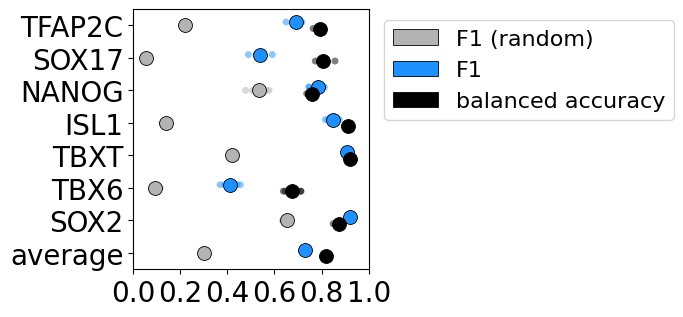

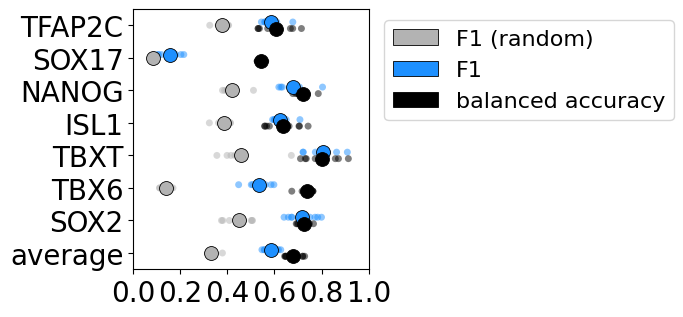

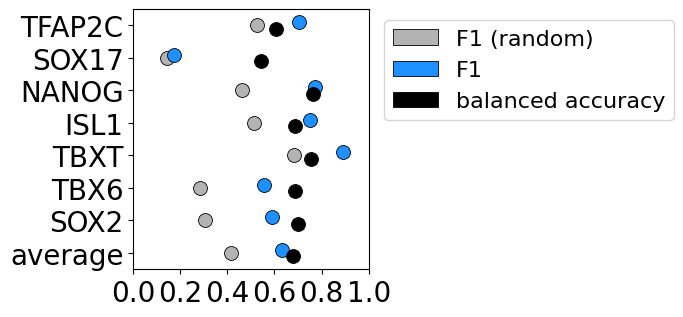

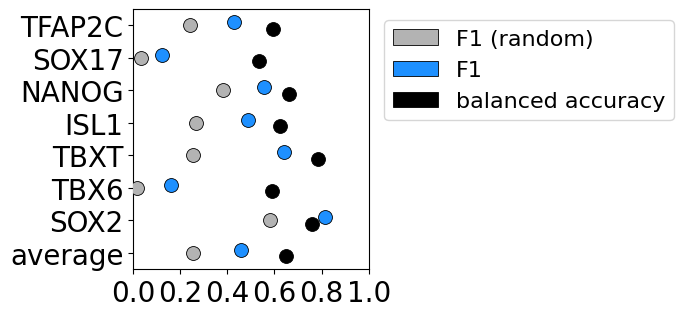

In [91]:
# Per-fold dot-plot comparison, same style as fig2n's "individual folds as dots"
# convention -- one panel per source (Exp20 B50, D1 pooled per triplet, D1 60k/90k
# totals), directly comparable since all use the same hyperparam/thresh_20/common_genes.
for src_label, perfold_df in perfold_by_source.items():
    print(src_label)
    IIF.plot_category_performance_perfold(
        perfold_df, labels_perf,
        dataDir + f'/expD1_VIB/selfCV_perfold_{src_label.replace(" ", "_")}.pdf',
        group_col='gene', tick_labels=labels_perf[:-1] + ['average'], legend=True)


In [92]:
# ============================================================
# Q2: does cross-experiment prediction generalize between disordered (expD1)
# and micropatterned (Exp20 B50) cultures, in both directions?
#
# (a) train on Exp20 B50, predict expD1 (pooled) -- signals aligned internally
#     by run_vib_cross_experiment (test_condition='ALL_D1'); output already in
#     Exp20's gene units, so compare directly against data_D1_aligned's
#     measured genes with thresh_20.
# (b) train on expD1 (pooled), predict Exp20 B50 -- output comes out in
#     data_D1_all's OWN (raw, unaligned) gene units per
#     run_vib_cross_experiment's convention, so gene_align_D1 (fit above) is
#     applied to the PREDICTION afterward to bring it onto Exp20's scale
#     before comparing with thresh_20.
#
# RECOMPUTE_Q2: retrain instead of loading cached runs -- needed after any change to
# expD1's filtering/alignment (the cached predictions are tied to the cell set they
# were computed on). Set back to False once rerun, or every run retrains.
# ============================================================

RECOMPUTE_Q2 = True
out_dir_cross = dataDir + '/expD1_vs_Exp20_VIB'

runs_20_to_D1 = IIF.run_vib_cross_experiment(
    data_B50_20, data_D1_all, signals, common_genes, hyperparam, N_run=3,
    out_dir=out_dir_cross, out_prefix='exp20_to_D1', recompute=RECOMPUTE_Q2,
    train_condition='B50', test_condition='ALL_D1', label='Exp20 B50 -> expD1')
pred_20_to_D1 = runs_20_to_D1['avg']

runs_D1_to_20 = IIF.run_vib_cross_experiment(
    data_D1_all, exp_result_20.data, signals, common_genes, hyperparam, N_run=3,
    out_dir=out_dir_cross, out_prefix='D1_to_exp20', recompute=RECOMPUTE_Q2,
    train_condition='ALL_D1', test_condition='B50', label='expD1 -> Exp20 B50')
pred_D1_to_20_full = runs_D1_to_20['avg']
pred_D1_to_20 = pred_D1_to_20_full[pred_D1_to_20_full['condition'] == 'B50'].copy()
pred_D1_to_20_aligned = IIF.apply_alignment(pred_D1_to_20, gene_align_D1, common_genes)

[Exp20 B50 -> expD1] Run 0/3
[Exp20 B50 -> expD1]   training on 30427 cells
[Exp20 B50 -> expD1]   predicting 97095 cells
[Exp20 B50 -> expD1] Elapsed time: 4.0 seconds
[Exp20 B50 -> expD1] Run 1/3
[Exp20 B50 -> expD1]   training on 30427 cells
[Exp20 B50 -> expD1]   predicting 97095 cells
[Exp20 B50 -> expD1] Elapsed time: 3.8 seconds
[Exp20 B50 -> expD1] Run 2/3
[Exp20 B50 -> expD1]   training on 30427 cells
[Exp20 B50 -> expD1]   predicting 97095 cells
[Exp20 B50 -> expD1] Elapsed time: 4.0 seconds
[expD1 -> Exp20 B50] Run 0/3
[expD1 -> Exp20 B50]   training on 97095 cells
[expD1 -> Exp20 B50]   predicting 84395 cells
[expD1 -> Exp20 B50] Elapsed time: 5.9 seconds
[expD1 -> Exp20 B50] Run 1/3
[expD1 -> Exp20 B50]   training on 97095 cells
[expD1 -> Exp20 B50]   predicting 84395 cells
[expD1 -> Exp20 B50] Elapsed time: 5.8 seconds
[expD1 -> Exp20 B50] Run 2/3
[expD1 -> Exp20 B50]   training on 97095 cells
[expD1 -> Exp20 B50]   predicting 84395 cells
[expD1 -> Exp20 B50] Elapsed time

Exp20 B50 -> expD1    F1=0.429  balanced_acc=0.589
marker_avg | f1_rand = 0.325
marker_avg | f1 = 0.429
marker_avg | balanced_accuracy = 0.589
expD1 -> Exp20 B50    F1=0.452  balanced_acc=0.601
marker_avg | f1_rand = 0.301
marker_avg | f1 = 0.452
marker_avg | balanced_accuracy = 0.601


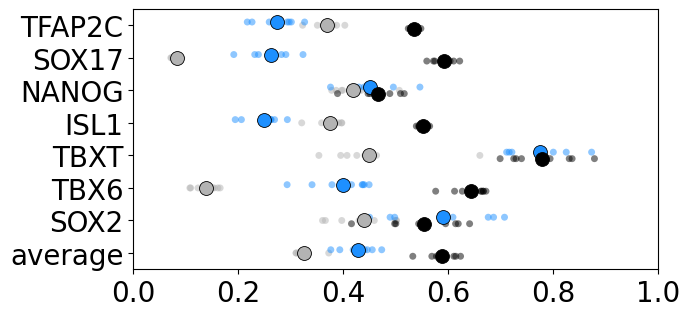

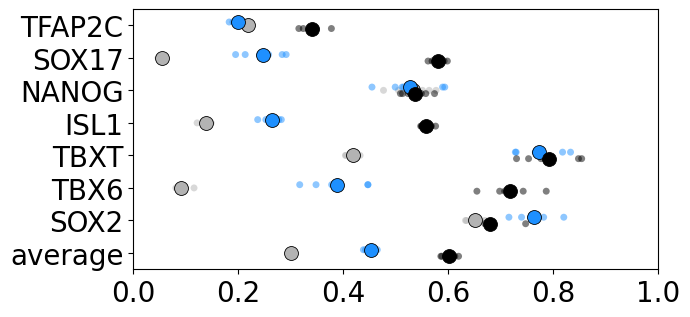

In [93]:
# Per-marker accuracy for both cross-experiment directions, same metric/style
# as Q1's self-CV numbers so they're directly comparable -- if cross-
# experiment accuracy is close to self-CV accuracy, the signaling->fate map
# transfers; if it's substantially worse, it doesn't. Exp20 B50 -> expD1 is scored
# per balanced triplet ('fold', see 'CV folds for expD1'), same folds as Q1's expD1.

perfold_20_to_D1 = IIF.compute_marker_performance_perfold(
    data_D1_aligned, pred_20_to_D1, data_D1_aligned['fold'].to_numpy(), common_genes, thresh_20)
perfold_20_to_D1 = IIF.add_group_avg(perfold_20_to_D1, ['f1_rand', 'f1', 'balanced_accuracy'], group_col='gene', avg_label='marker_avg')

perfold_D1_to_20 = IIF.compute_marker_performance_perfold(
    data_B50_20, pred_D1_to_20_aligned, data_B50_20['Colony'].to_numpy(), common_genes, thresh_20)
perfold_D1_to_20 = IIF.add_group_avg(perfold_D1_to_20, ['f1_rand', 'f1', 'balanced_accuracy'], group_col='gene', avg_label='marker_avg')

perfold_by_source['Exp20 B50 -> expD1'] = perfold_20_to_D1
perfold_by_source['expD1 -> Exp20 B50'] = perfold_D1_to_20

for src_label in ['Exp20 B50 -> expD1', 'expD1 -> Exp20 B50']:
    avg_row = perfold_by_source[src_label][perfold_by_source[src_label]['gene'] == 'marker_avg']
    print(f"{src_label:20s}  F1={avg_row['f1'].mean():.3f}  balanced_acc={avg_row['balanced_accuracy'].mean():.3f}")

    IIF.plot_category_performance_perfold(
        perfold_by_source[src_label], labels_perf,
        dataDir + f'/expD1_vs_Exp20_VIB/crossCV_perfold_{src_label.replace(" ", "_").replace(">", "to")}.pdf',
        group_col='gene', tick_labels=labels_perf[:-1] + ['average'])


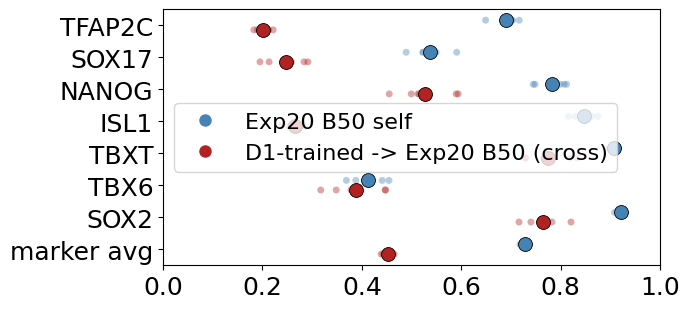

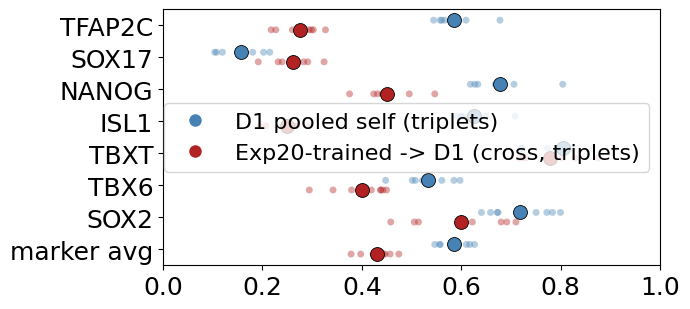

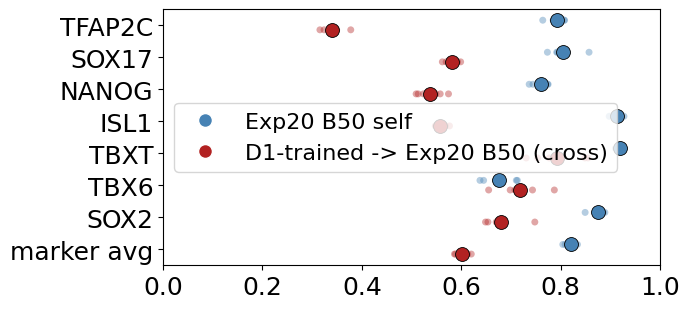

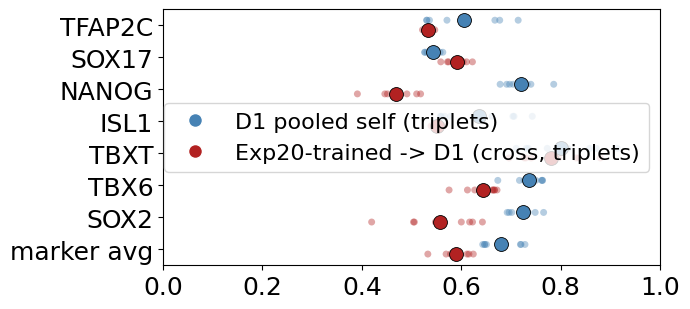

In [95]:
# ============================================================
# Self vs. cross-experiment accuracy, one metric per plot -- each population's own
# self-CV directly compared against the cross-experiment prediction ON THAT SAME
# population, using IIF.plot_perfold_comparison (built for exactly this). No
# retraining, just re-scoring already-computed predictions:
#   - Exp20 B50: self (6 colonies) vs expD1-trained -> Exp20 B50 (same 6 colonies)
#   - expD1 pooled: self (8 balanced triplets) vs Exp20-trained -> expD1 (same triplets),
#     both on the 'other'-excluded subset, same as Q1
# ============================================================

perfold_20_to_D1_scored = perfold_scores(data_D1_scored, pred_20_to_D1, 'fold')

comparisons = [
    ('Exp20B50', perfold_by_source['Exp20 B50'], perfold_D1_to_20,
     'Exp20 B50 self', 'D1-trained -> Exp20 B50 (cross)'),
    ('D1pooled', perfold_by_source['D1 pooled'], perfold_20_to_D1_scored,
     'D1 pooled self (triplets)', 'Exp20-trained -> D1 (cross, triplets)'),
]

for score in ['f1', 'balanced_accuracy']:
    for name, self_df, cross_df, self_label, cross_label in comparisons:
        IIF.plot_perfold_comparison(
            [(self_df, score, 'steelblue'), (cross_df, score, 'firebrick')],
            'gene', labels_perf,
            dataDir + f'/expD1_vs_Exp20_VIB/selfvscross_{name}_{score}.pdf',
            legend_labels=[self_label, cross_label],
            tick_labels=labels_perf[:-1] + ['marker avg'])



Exp20 B50 self
            spearman     F1  F1 chance  bal_acc
marker                                         
TFAP2C         0.561  0.690      0.218    0.792
SOX17          0.638  0.537      0.055    0.805
NANOG          0.668  0.783      0.534    0.760
ISL1           0.736  0.847      0.138    0.913
TBXT           0.867  0.907      0.419    0.920
TBX6           0.685  0.413      0.092    0.675
SOX2           0.834  0.921      0.652    0.874
marker_avg     0.713  0.728      0.301    0.820

expD1 -> Exp20 B50
            spearman     F1  F1 chance  bal_acc
marker                                         
TFAP2C        -0.286  0.201      0.218    0.341
SOX17          0.321  0.247      0.055    0.581
NANOG          0.232  0.528      0.534    0.538
ISL1          -0.029  0.265      0.138    0.558
TBXT           0.799  0.774      0.418    0.792
TBX6           0.556  0.389      0.092    0.719
SOX2           0.294  0.763      0.652    0.681
marker_avg     0.270  0.452      0.301    0.601

D1 

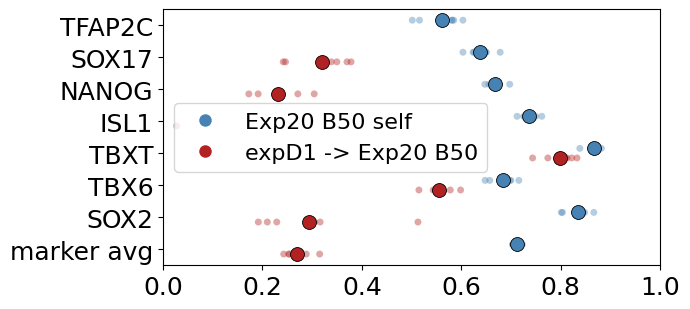

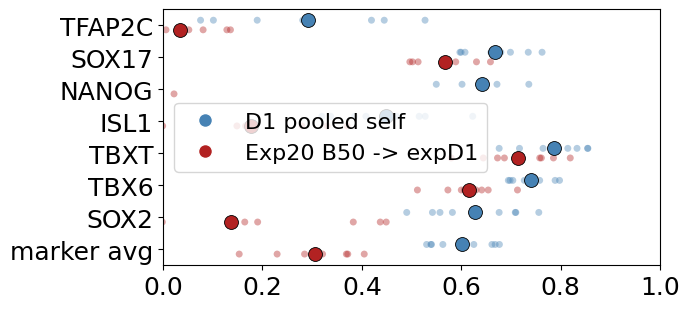

In [96]:
# ============================================================
# Threshold-free check: per-cell Spearman correlation between predicted and measured
# intensity, per marker and fold. Rank-based, so unaffected by any scale-and-shift of
# measured or predicted values -- i.e. by the marker alignment and by where thresh_20
# cuts. If a marker's F1 / balanced-accuracy lead (e.g. TBXT over ISL1) persists here,
# it's not a thresholding artifact; if it shrinks, thresholding (marker alignment) was
# driving it. Same cells as the F1 scores ('other'-excluded subset), same folds
# (Exp20 B50: 6 colonies; expD1: 8 balanced triplets).
# ============================================================
from scipy.stats import spearmanr

def spearman_perfold(data_scored, pred, fold_col):
    """Per-fold, per-marker Spearman correlation of pred vs data_scored (rows matched by
    index), plus the per-fold marker average, in the same long format as
    compute_marker_performance_perfold."""
    pred = pred.loc[data_scored.index]
    records = []
    for fold in np.unique(data_scored[fold_col]):
        in_fold = (data_scored[fold_col] == fold).to_numpy()
        for marker in common_genes:
            rho = spearmanr(data_scored[marker].to_numpy()[in_fold], pred[marker].to_numpy()[in_fold])[0]
            records.append({'fold': fold, 'gene': marker, 'spearman': rho})
    return IIF.add_group_avg(pd.DataFrame(records), ['spearman'], group_col='gene', avg_label='marker_avg')

data_B50_20_scored = scored_subset(data_B50_20, thresh_20)
spearman_by_source = {
    'Exp20 B50 self':   spearman_perfold(data_B50_20_scored, pred_selfB50_20, 'Colony'),
    'expD1 -> Exp20 B50': spearman_perfold(data_B50_20_scored, pred_D1_to_20_aligned, 'Colony'),
    'D1 pooled self':   spearman_perfold(data_D1_scored, pred_self_D1, 'fold'),
    'Exp20 B50 -> expD1': spearman_perfold(data_D1_scored, pred_20_to_D1, 'fold'),
}
f1_sources = {'Exp20 B50 self': perfold_by_source['Exp20 B50'],
              'expD1 -> Exp20 B50': perfold_D1_to_20,
              'D1 pooled self': perfold_by_source['D1 pooled'],
              'Exp20 B50 -> expD1': perfold_20_to_D1_scored}

# Mean over folds, per marker: Spearman next to F1 and balanced accuracy for each source
rows = []
for src, sp in spearman_by_source.items():
    sc = f1_sources[src]
    for marker in labels_perf:
        rows.append({'source': src, 'marker': marker,
                     'spearman': sp.loc[sp['gene'] == marker, 'spearman'].mean(),
                     'F1': sc.loc[sc['gene'] == marker, 'f1'].mean(),
                     'F1 chance': sc.loc[sc['gene'] == marker, 'f1_rand'].mean(),
                     'bal_acc': sc.loc[sc['gene'] == marker, 'balanced_accuracy'].mean()})
comparison = pd.DataFrame(rows).set_index(['source', 'marker']).round(3)
for src in spearman_by_source:
    print(f"\n{src}")
    print(comparison.loc[src].to_string())

# Self vs cross, Spearman, same layout as 'Self vs. cross-experiment accuracy'
for name, self_src, cross_src in [('Exp20B50', 'Exp20 B50 self', 'expD1 -> Exp20 B50'),
                                  ('D1pooled', 'D1 pooled self', 'Exp20 B50 -> expD1')]:
    IIF.plot_perfold_comparison(
        [(spearman_by_source[self_src], 'spearman', 'steelblue'),
         (spearman_by_source[cross_src], 'spearman', 'firebrick')],
        'gene', labels_perf,
        dataDir + f'/expD1_vs_Exp20_VIB/selfvscross_{name}_spearman.pdf',
        legend_labels=[self_src, cross_src],
        tick_labels=labels_perf[:-1] + ['marker avg'])



Exp20 B50 self
              auc  measured_pos_frac  pred_pos_frac  pred / measured     F1
gene                                                                       
TFAP2C      0.868              0.218          0.191            0.876  0.690
SOX17       0.951              0.055          0.078            1.434  0.537
NANOG       0.842              0.534          0.565            1.057  0.783
ISL1        0.981              0.138          0.139            1.006  0.847
TBXT        0.974              0.419          0.430            1.027  0.907
TBX6        0.888              0.092          0.083            0.906  0.413
SOX2        0.961              0.652          0.681            1.045  0.921
marker_avg  0.924                NaN            NaN              NaN  0.728

expD1 -> Exp20 B50
              auc  measured_pos_frac  pred_pos_frac  pred / measured     F1
gene                                                                       
TFAP2C      0.315              0.218          0.649 

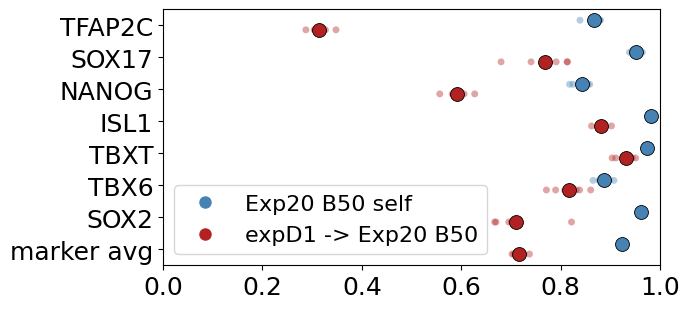

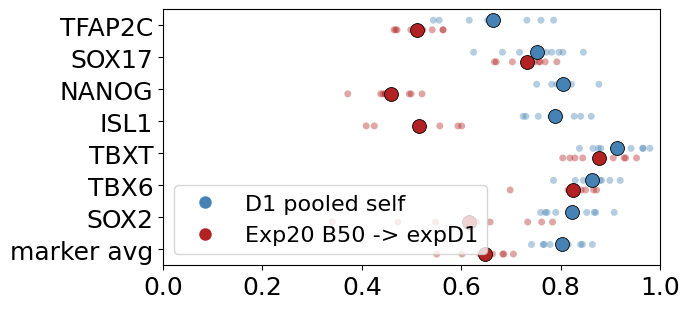

In [97]:
# ============================================================
# Separation vs. narrowing check. The model predicts roughly the mean gene level for a
# given signal combination, so predictions are narrower than the measured distribution;
# a rare, partly-predictable population can then be ranked correctly but still predicted
# BELOW thresh_20 (low F1 despite good separation). Two checks per marker and fold:
#   - AUC: how well predicted values rank measured-positive above measured-negative
#     cells (measured call = thresh_20). Independent of where the threshold sits on the
#     predictions and of ordering within the background peak.
#     High AUC + low F1 -> narrowing/threshold problem; low AUC -> can't separate.
#   - predicted vs measured positive fraction (both at thresh_20). Predicted << measured
#     -> positives predicted below threshold.
# Same cells ('other'-excluded) and folds as the F1 scores.
# ============================================================

def separation_perfold(data_scored, pred, fold_col):
    """Per-fold, per-marker AUC of predicted values against the measured thresh_20 call,
    plus measured and predicted positive fractions, in long format. AUC is NaN for a
    fold where a marker has only one measured class."""
    pred = pred.loc[data_scored.index]
    records = []
    for fold in np.unique(data_scored[fold_col]):
        in_fold = (data_scored[fold_col] == fold).to_numpy()
        for marker in common_genes:
            measured_pos = data_scored[marker].to_numpy()[in_fold] > thresh_20[marker]
            pred_vals = pred[marker].to_numpy()[in_fold]
            auc = roc_auc_score(measured_pos, pred_vals) if 0 < measured_pos.mean() < 1 else np.nan
            records.append({'fold': fold, 'gene': marker, 'auc': auc,
                            'measured_pos_frac': measured_pos.mean(),
                            'pred_pos_frac': (pred_vals > thresh_20[marker]).mean()})
    return pd.DataFrame(records)

data_B50_20_scored = scored_subset(data_B50_20, thresh_20)
sources_sep = {
    'Exp20 B50 self':     (data_B50_20_scored, pred_selfB50_20, 'Colony', perfold_by_source['Exp20 B50']),
    'expD1 -> Exp20 B50': (data_B50_20_scored, pred_D1_to_20_aligned, 'Colony', perfold_D1_to_20),
    'D1 pooled self':     (data_D1_scored, pred_self_D1, 'fold', perfold_by_source['D1 pooled']),
    'Exp20 B50 -> expD1': (data_D1_scored, pred_20_to_D1, 'fold', perfold_20_to_D1_scored),
}

separation_by_source = {}
for src, (data_scored, pred, fold_col, f1_df) in sources_sep.items():
    sep = separation_perfold(data_scored, pred, fold_col)
    separation_by_source[src] = IIF.add_group_avg(sep, ['auc'], group_col='gene', avg_label='marker_avg')
    table = sep.groupby('gene')[['auc', 'measured_pos_frac', 'pred_pos_frac']].mean()
    table['pred / measured'] = table['pred_pos_frac'] / table['measured_pos_frac']
    table['F1'] = f1_df[f1_df['gene'].isin(common_genes)].groupby('gene')['f1'].mean()
    table.loc['marker_avg'] = [table['auc'].mean(), np.nan, np.nan, np.nan, table['F1'].mean()]
    print(f"\n{src}")
    print(table.loc[common_genes + ['marker_avg']].round(3).to_string())

# Self vs cross, AUC, same layout as 'Self vs. cross-experiment accuracy'
for name, self_src, cross_src in [('Exp20B50', 'Exp20 B50 self', 'expD1 -> Exp20 B50'),
                                  ('D1pooled', 'D1 pooled self', 'Exp20 B50 -> expD1')]:
    IIF.plot_perfold_comparison(
        [(separation_by_source[self_src], 'auc', 'steelblue'),
         (separation_by_source[cross_src], 'auc', 'firebrick')],
        'gene', labels_perf,
        dataDir + f'/expD1_vs_Exp20_VIB/selfvscross_{name}_auc.pdf',
        legend_labels=[self_src, cross_src],
        tick_labels=labels_perf[:-1] + ['marker avg'])


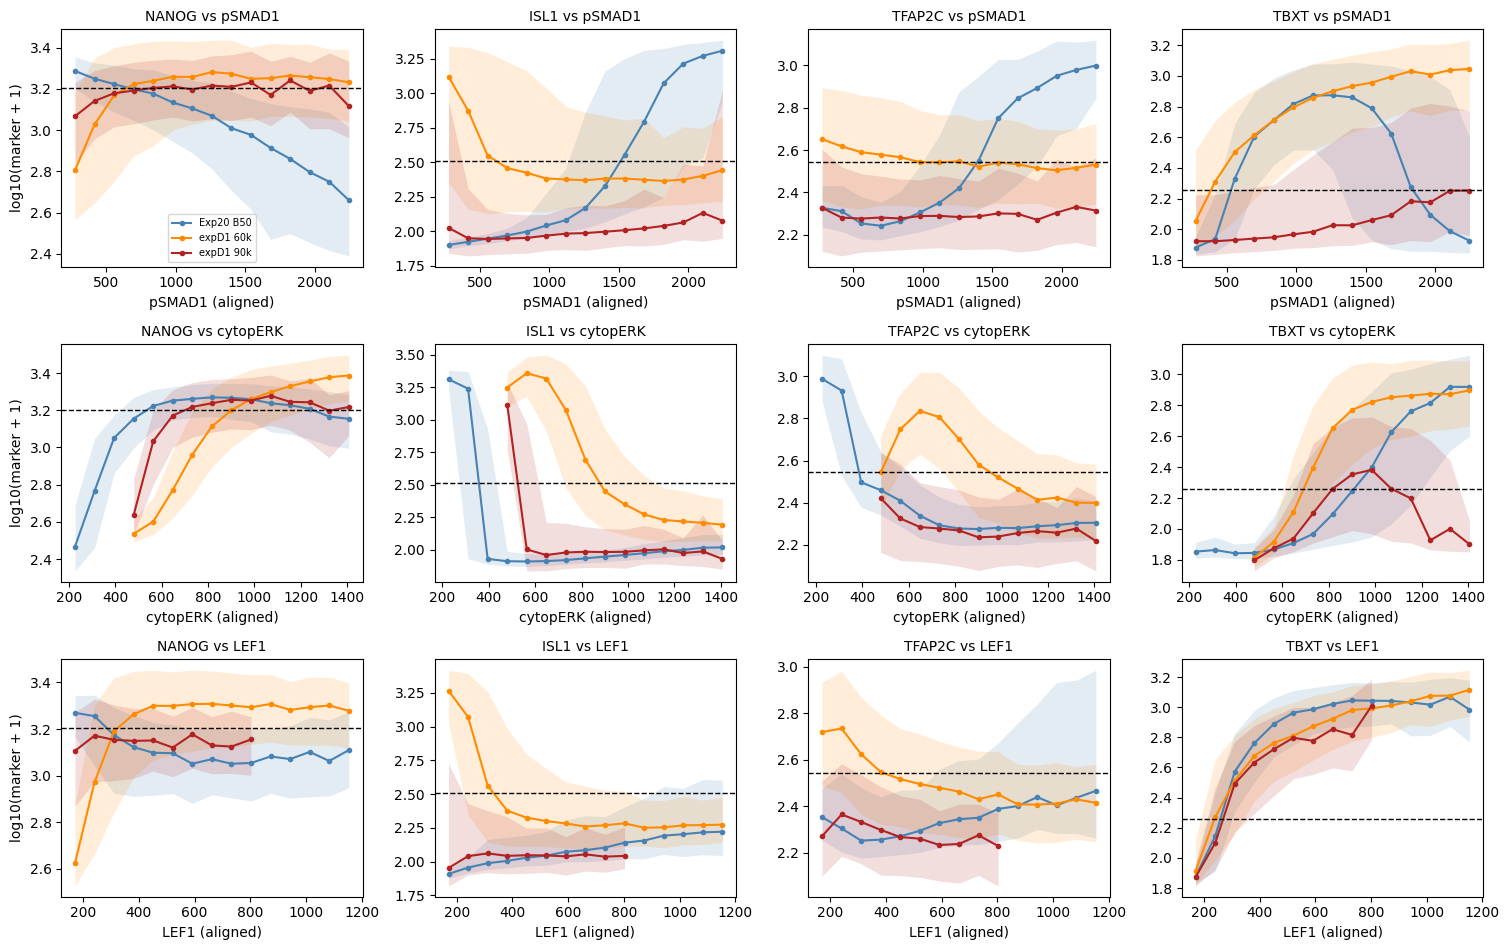

In [ ]:
# ============================================================
# Model-free check of the signal -> marker relationship, Exp20 B50 vs expD1, both in
# Exp20-aligned units. For each (signal, marker) pair: cells binned by signal level
# (shared bins, spanning Exp20 B50's 2nd-98th percentile), median log10(marker + 1) per
# bin with the 25-75% band. expD1 60k and 90k drawn separately (cytopERK differs ~2.6x
# between them). Only bins with >= MIN_CELLS_PER_BIN cells are drawn.
#   curves shifted left/right  -> points to the SIGNAL alignment
#   curves shifted up/down     -> points to the MARKER alignment
#   curves differently shaped  -> the relationship itself differs
# Dashed horizontal line: thresh_20 for the marker. Edit SIGNALS_BINNED / MARKERS_BINNED
# to look at other pairs.
# ============================================================

SIGNALS_BINNED = ['pSMAD1', 'cytopERK', 'LEF1']
MARKERS_BINNED = ['NANOG', 'ISL1', 'TFAP2C', 'TBXT']
N_BINS = 15
MIN_CELLS_PER_BIN = 50

def binned_profile(sig_vals, marker_vals, edges):
    """Bin centers, median and 25/75th percentiles of log10(max(marker, 0) + 1) per signal
    bin; NaN for bins with fewer than MIN_CELLS_PER_BIN cells."""
    log_marker = np.log10(np.clip(marker_vals, 0, None) + 1)
    which = np.digitize(sig_vals, edges) - 1
    stats = np.full((len(edges) - 1, 3), np.nan)
    for b in range(len(edges) - 1):
        in_bin = log_marker[which == b]
        if len(in_bin) >= MIN_CELLS_PER_BIN:
            stats[b] = np.percentile(in_bin, [25, 50, 75])
    return (edges[:-1] + edges[1:]) / 2, stats

curves_binned = [('Exp20 B50', data_B50_20, 'steelblue'),
                 ('expD1 60k', data_D1_aligned[data_D1_aligned['condition'] == '60k'], 'darkorange'),
                 ('expD1 90k', data_D1_aligned[data_D1_aligned['condition'] == '90k'], 'firebrick')]

fig, axes = plt.subplots(len(SIGNALS_BINNED), len(MARKERS_BINNED),
                         figsize=(3.8 * len(MARKERS_BINNED), 3.2 * len(SIGNALS_BINNED)), squeeze=False)
for r, sig in enumerate(SIGNALS_BINNED):
    edges = np.linspace(*np.percentile(data_B50_20[sig].dropna(), [2, 98]), N_BINS + 1)
    for c, marker in enumerate(MARKERS_BINNED):
        ax = axes[r, c]
        for label, df, color in curves_binned:
            ok = df[sig].notna() & df[marker].notna()
            centers, stats = binned_profile(df.loc[ok, sig].to_numpy(), df.loc[ok, marker].to_numpy(), edges)
            ax.plot(centers, stats[:, 1], '-o', ms=3, color=color, label=label)
            ax.fill_between(centers, stats[:, 0], stats[:, 2], color=color, alpha=0.15, linewidth=0)
        ax.axhline(np.log10(thresh_20[marker] + 1), color='black', linestyle='--', lw=1)
        ax.set_title(f'{marker} vs {sig}', fontsize=10)
        ax.set_xlabel(f'{sig} (aligned)')
        if c == 0:
            ax.set_ylabel('log10(marker + 1)')
        if r == 0 and c == 0:
            ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
